<a href="https://colab.research.google.com/github/tasnimchembu-rgb/awesome-drug-discovery/blob/main/GCI_Competition_Working.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_path = '/content/drive/MyDrive'

print("Google Drive Connected Successfully!")
print("\nFiles and Folders in MyDrive:\n")

print(os.listdir(drive_path))

Google Drive Connected Successfully!

Files and Folders in MyDrive:

['Colab Notebooks', 'Chemistry 3rd year', 'Classroom', 'AI_Drug_Discovery_Research', 'AI_drug_discovery_backup', 'AI_DRUG_DISCOVERY_PORTFOLIO', 'GCI_World_2026']


In [ ]:
competition_path = '/content/drive/MyDrive/GCI_World_2026/Competition'

print("Competition Folder Contents:\n")

print(os.listdir(competition_path))

Competition Folder Contents:

['HomeCredit_columns_description.xlsx', 'README.ipynb', 'tutorial.ipynb', 'input']


In [ ]:
input_path = os.path.join(competition_path, 'input')

print("Dataset Files:\n")

print(os.listdir(input_path))

Dataset Files:

['sample_submission.csv', 'test.csv', 'train.csv']


In [ ]:
# Numerical computation
import numpy as np

# Data manipulation and analysis
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and directory management
import os
from pathlib import Path

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Main competition directory
competition_path = Path(
    '/content/drive/MyDrive/GCI_World_2026/Competition'
)

# Dataset directory
input_path = competition_path / 'input'

# Individual dataset paths
train_path = input_path / 'train.csv'

test_path = input_path / 'test.csv'

submission_path = input_path / 'sample_submission.csv'

print("Competition paths defined successfully!")

Competition paths defined successfully!


In [ ]:
# Load training dataset
train = pd.read_csv(train_path)

# Load testing dataset
test = pd.read_csv(test_path)

# Load sample submission
sample_submission = pd.read_csv(submission_path)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
print("TRAIN DATASET SHAPE:")
print(train.shape)

print("\nTEST DATASET SHAPE:")
print(test.shape)

print("\nSAMPLE SUBMISSION SHAPE:")
print(sample_submission.shape)

TRAIN DATASET SHAPE:
(171202, 34)

TEST DATASET SHAPE:
(61500, 33)

SAMPLE SUBMISSION SHAPE:
(61500, 2)


In [ ]:
train.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [ ]:
test.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


In [ ]:
sample_submission.head()

,SK_ID_CURR,TARGET
0,171202,0.5
1,171203,0.5
2,171204,0.5
3,171205,0.5
4,171206,0.5


In [ ]:
print("Total number of columns:", len(train.columns))

print("\nColumn Names:\n")

for column in train.columns:
    print(column)

Total number of columns: 34

Column Names:

SK_ID_CURR
NAME_CONTRACT_TYPE
CODE_GENDER
CNT_CHILDREN
AMT_INCOME_TOTAL
AMT_CREDIT
AMT_ANNUITY
AMT_GOODS_PRICE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
REGION_POPULATION_RELATIVE
DAYS_BIRTH
DAYS_EMPLOYED
DAYS_REGISTRATION
DAYS_ID_PUBLISH
OWN_CAR_AGE
FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_WORK_PHONE
OCCUPATION_TYPE
CNT_FAM_MEMBERS
REGION_RATING_CLIENT
ORGANIZATION_TYPE
EXT_SOURCE_1
EXT_SOURCE_2
EXT_SOURCE_3
DAYS_LAST_PHONE_CHANGE
AMT_REQ_CREDIT_BUREAU_HOUR
AMT_REQ_CREDIT_BUREAU_MON
AMT_REQ_CREDIT_BUREAU_QRT
AMT_REQ_CREDIT_BUREAU_YEAR
TARGET


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  object 
 2   CODE_GENDER                 171202 non-null  object 
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  object 
 9   NAME_EDUCATION_TYPE         171202 non-null  object 
 10  NAME_FAMILY_STATUS          171202 non-null  object 
 11  NAME_HOUSING_TYPE           171202 non-null  object 
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH    

In [ ]:
train.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


In [ ]:
print("Sample Submission Columns:")
print(sample_submission.columns.tolist())

print("\nFirst Five Rows:")
display(sample_submission.head())

Sample Submission Columns:
['SK_ID_CURR', 'TARGET']

First Five Rows:


,SK_ID_CURR,TARGET
0,171202,0.5
1,171203,0.5
2,171204,0.5
3,171205,0.5
4,171206,0.5


In [ ]:
# Check dataset dimensions

print("TRAIN DATASET:")
print("Shape:", train.shape)

print("\nTEST DATASET:")
print("Shape:", test.shape)

print("\nSAMPLE SUBMISSION:")
print("Shape:", sample_submission.shape)


# Check target variable

print("\nTARGET VARIABLE DISTRIBUTION:")
print(train['TARGET'].value_counts(dropna=False))

TRAIN DATASET:
Shape: (171202, 34)

TEST DATASET:
Shape: (61500, 33)

SAMPLE SUBMISSION:
Shape: (61500, 2)

TARGET VARIABLE DISTRIBUTION:
TARGET
0    157381
1     13821
Name: count, dtype: int64


In [ ]:
# STEP 4.2.1
# Missing Value Analysis - Training Dataset

missing_train = pd.DataFrame({
    'Missing_Count': train.isnull().sum(),
    'Missing_Percentage': train.isnull().mean() * 100
})

missing_train = missing_train.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("MISSING VALUE ANALYSIS - TRAIN DATASET")

display(missing_train)

MISSING VALUE ANALYSIS - TRAIN DATASET


,Missing_Count,Missing_Percentage
EXT_SOURCE_1,118928,69.466478
OWN_CAR_AGE,112992,65.999229
EXT_SOURCE_3,54586,31.883973
AMT_REQ_CREDIT_BUREAU_MON,23116,13.502179
AMT_REQ_CREDIT_BUREAU_QRT,23116,13.502179
AMT_REQ_CREDIT_BUREAU_HOUR,23116,13.502179
AMT_REQ_CREDIT_BUREAU_YEAR,23116,13.502179
EXT_SOURCE_2,369,0.215535
CNT_FAM_MEMBERS,2,0.001168
SK_ID_CURR,0,0.000000


In [ ]:
# STEP 4.2.2
# Missing Value Analysis - Testing Dataset

missing_test = pd.DataFrame({
    'Missing_Count': test.isnull().sum(),
    'Missing_Percentage': test.isnull().mean() * 100
})

missing_test = missing_test.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("MISSING VALUE ANALYSIS - TEST DATASET")

display(missing_test)

MISSING VALUE ANALYSIS - TEST DATASET


,Missing_Count,Missing_Percentage
EXT_SOURCE_1,42912,69.775610
OWN_CAR_AGE,40909,66.518699
EXT_SOURCE_3,19690,32.016260
AMT_REQ_CREDIT_BUREAU_QRT,8513,13.842276
AMT_REQ_CREDIT_BUREAU_MON,8513,13.842276
AMT_REQ_CREDIT_BUREAU_HOUR,8513,13.842276
AMT_REQ_CREDIT_BUREAU_YEAR,8513,13.842276
EXT_SOURCE_2,130,0.211382
SK_ID_CURR,0,0.000000
NAME_CONTRACT_TYPE,0,0.000000


In [ ]:
# STEP 4.2.3
# Compare Missing Values in Train and Test

missing_comparison = pd.DataFrame({
    'Train_Missing_Count': train.isnull().sum(),
    'Train_Missing_Percentage': train.isnull().mean() * 100,
    'Test_Missing_Count': test.isnull().sum(),
    'Test_Missing_Percentage': test.isnull().mean() * 100
})

missing_comparison = missing_comparison.sort_values(
    by='Train_Missing_Percentage',
    ascending=False
)

display(missing_comparison)

,Train_Missing_Count,Train_Missing_Percentage,Test_Missing_Count,Test_Missing_Percentage
EXT_SOURCE_1,118928,69.466478,42912.0,69.775610
OWN_CAR_AGE,112992,65.999229,40909.0,66.518699
EXT_SOURCE_3,54586,31.883973,19690.0,32.016260
AMT_REQ_CREDIT_BUREAU_HOUR,23116,13.502179,8513.0,13.842276
AMT_REQ_CREDIT_BUREAU_QRT,23116,13.502179,8513.0,13.842276
AMT_REQ_CREDIT_BUREAU_MON,23116,13.502179,8513.0,13.842276
AMT_REQ_CREDIT_BUREAU_YEAR,23116,13.502179,8513.0,13.842276
EXT_SOURCE_2,369,0.215535,130.0,0.211382
CNT_FAM_MEMBERS,2,0.001168,0.0,0.000000
AMT_ANNUITY,0,0.000000,0.0,0.000000


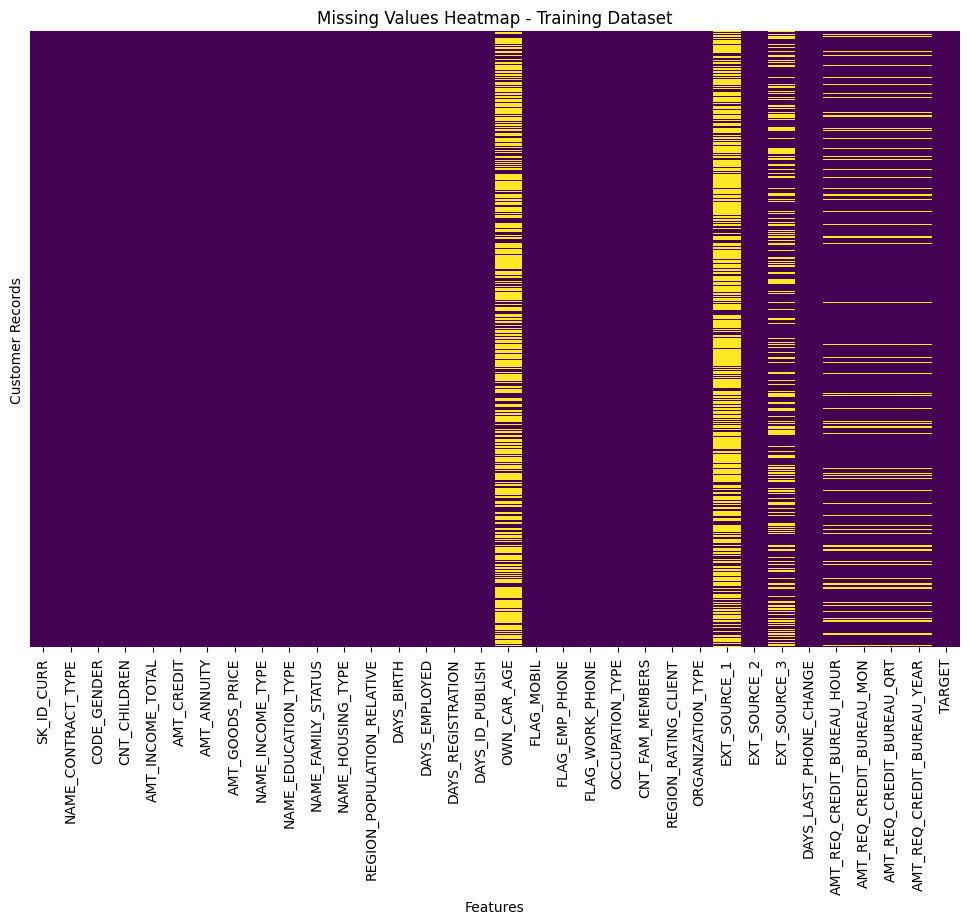

In [ ]:
# STEP 4.2.4
# Visualize Missing Values

plt.figure(figsize=(12, 8))

sns.heatmap(
    train.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap - Training Dataset')

plt.xlabel('Features')
plt.ylabel('Customer Records')

plt.show()

In [ ]:
# STEP 4.3.1
# Exact Duplicate Row Analysis

train_duplicates = train.duplicated().sum()
test_duplicates = test.duplicated().sum()

print("DUPLICATE ROW ANALYSIS")

print("\nTRAIN DATASET")
print("Total Rows:", len(train))
print("Exact Duplicate Rows:", train_duplicates)
print("Duplicate Percentage:",
      (train_duplicates / len(train)) * 100)

print("\nTEST DATASET")
print("Total Rows:", len(test))
print("Exact Duplicate Rows:", test_duplicates)
print("Duplicate Percentage:",
      (test_duplicates / len(test)) * 100)

DUPLICATE ROW ANALYSIS

TRAIN DATASET
Total Rows: 171202
Exact Duplicate Rows: 0
Duplicate Percentage: 0.0

TEST DATASET
Total Rows: 61500
Exact Duplicate Rows: 0
Duplicate Percentage: 0.0


In [ ]:
# STEP 4.3.2
# Customer ID Uniqueness Analysis

print("CUSTOMER ID UNIQUENESS ANALYSIS")

# 1. Check duplicate IDs in Training Dataset
train_duplicate_ids = train['SK_ID_CURR'].duplicated().sum()

# 2. Check duplicate IDs in Testing Dataset
test_duplicate_ids = test['SK_ID_CURR'].duplicated().sum()

# 3. Count unique customer IDs
train_unique_ids = train['SK_ID_CURR'].nunique()
test_unique_ids = test['SK_ID_CURR'].nunique()

print("\nTRAIN DATASET")
print("Total Customer IDs:", len(train))
print("Unique Customer IDs:", train_unique_ids)
print("Duplicate Customer IDs:", train_duplicate_ids)

print("\nTEST DATASET")
print("Total Customer IDs:", len(test))
print("Unique Customer IDs:", test_unique_ids)
print("Duplicate Customer IDs:", test_duplicate_ids)

# 4. Check ID overlap between Train and Test
common_ids = set(train['SK_ID_CURR']).intersection(
    set(test['SK_ID_CURR'])
)

print("\nTRAIN-TEST ID OVERLAP")
print("Common Customer IDs:", len(common_ids))

CUSTOMER ID UNIQUENESS ANALYSIS

TRAIN DATASET
Total Customer IDs: 171202
Unique Customer IDs: 171202
Duplicate Customer IDs: 0

TEST DATASET
Total Customer IDs: 61500
Unique Customer IDs: 61500
Duplicate Customer IDs: 0

TRAIN-TEST ID OVERLAP
Common Customer IDs: 0


In [ ]:
# STEP 4.4.1
# Identify Numerical Features

# Select numerical columns from Training Dataset
numerical_columns = train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Exclude Customer ID and Target
numerical_features = [
    col for col in numerical_columns
    if col not in ['SK_ID_CURR', 'TARGET']
]

print("NUMERICAL FEATURE IDENTIFICATION")

print("\nTotal Numerical Columns:", len(numerical_columns))

print("Total Numerical Features (excluding ID and Target):",
      len(numerical_features))

print("\nNumerical Features:")

for feature in numerical_features:
    print(feature)

NUMERICAL FEATURE IDENTIFICATION

Total Numerical Columns: 26
Total Numerical Features (excluding ID and Target): 24

Numerical Features:
CNT_CHILDREN
AMT_INCOME_TOTAL
AMT_CREDIT
AMT_ANNUITY
AMT_GOODS_PRICE
REGION_POPULATION_RELATIVE
DAYS_BIRTH
DAYS_EMPLOYED
DAYS_REGISTRATION
DAYS_ID_PUBLISH
OWN_CAR_AGE
FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_WORK_PHONE
CNT_FAM_MEMBERS
REGION_RATING_CLIENT
EXT_SOURCE_1
EXT_SOURCE_2
EXT_SOURCE_3
DAYS_LAST_PHONE_CHANGE
AMT_REQ_CREDIT_BUREAU_HOUR
AMT_REQ_CREDIT_BUREAU_MON
AMT_REQ_CREDIT_BUREAU_QRT
AMT_REQ_CREDIT_BUREAU_YEAR


In [ ]:
# STEP 4.4.2
# Descriptive Statistical Analysis

# Calculate descriptive statistics
numerical_summary = train[numerical_features].describe().T

# Calculate missing value counts
numerical_summary['Missing_Count'] = (
    train[numerical_features].isnull().sum()
)

# Calculate missing value percentages
numerical_summary['Missing_Percentage'] = (
    train[numerical_features].isnull().mean() * 100
)

# Display the statistical summary
print("DESCRIPTIVE STATISTICAL ANALYSIS")

display(numerical_summary)

DESCRIPTIVE STATISTICAL ANALYSIS


,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
CNT_CHILDREN,171202.0,0.416490,0.720138,0.000000e+00,0.000000,0.000000,1.000000,1.400000e+01,0,0.000000
AMT_INCOME_TOTAL,171202.0,168371.213673,107234.793540,2.610000e+04,112500.000000,146250.000000,202500.000000,1.350000e+07,0,0.000000
AMT_CREDIT,171202.0,599129.309526,402816.996913,4.500000e+04,270000.000000,514602.000000,808650.000000,4.050000e+06,0,0.000000
AMT_ANNUITY,171202.0,27120.065953,14450.252689,1.980000e+03,16546.500000,24916.500000,34600.500000,1.709865e+05,0,0.000000
AMT_GOODS_PRICE,171202.0,538056.896715,368572.734241,4.500000e+04,238500.000000,450000.000000,679500.000000,2.254500e+06,0,0.000000
REGION_POPULATION_RELATIVE,171202.0,0.020839,0.013803,2.900000e-04,0.010006,0.018850,0.028663,7.250800e-02,0,0.000000
DAYS_BIRTH,171202.0,-16045.340504,4363.792228,-2.522900e+04,-19686.000000,-15778.000000,-12420.000000,-7.673000e+03,0,0.000000
DAYS_EMPLOYED,171202.0,63960.411969,141401.513149,-1.791200e+04,-2772.000000,-1215.000000,-288.000000,3.652430e+05,0,0.000000
DAYS_REGISTRATION,171202.0,-4994.982524,3525.760241,-2.467200e+04,-7490.000000,-4515.000000,-2008.000000,0.000000e+00,0,0.000000
DAYS_ID_PUBLISH,171202.0,-2990.486005,1509.694163,-7.197000e+03,-4297.000000,-3247.000000,-1714.250000,0.000000e+00,0,0.000000


In [ ]:
# STEP 4.4.3
# DAYS_EMPLOYED Special Value Investigation

print("DAYS_EMPLOYED INVESTIGATION")

# 1. Check the frequency of the maximum value
special_value_count = (
    train['DAYS_EMPLOYED'] == 365243
).sum()

print("\n1. Special Value Frequency")
print("Value 365243 Count:", special_value_count)

# 2. Count positive values
positive_count = (
    train['DAYS_EMPLOYED'] > 0
).sum()

print("\n2. Positive Values")
print("Positive Count:", positive_count)

# 3. Count negative values
negative_count = (
    train['DAYS_EMPLOYED'] < 0
).sum()

print("\n3. Negative Values")
print("Negative Count:", negative_count)

# 4. Count zero values
zero_count = (
    train['DAYS_EMPLOYED'] == 0
).sum()

print("\n4. Zero Values")
print("Zero Count:", zero_count)

# 5. Calculate statistics excluding the special value
days_employed_clean = train.loc[
    train['DAYS_EMPLOYED'] != 365243,
    'DAYS_EMPLOYED'
]

print("\n5. Statistics Excluding 365243")
print("Mean:", days_employed_clean.mean())
print("Median:", days_employed_clean.median())
print("Minimum:", days_employed_clean.min())
print("Maximum:", days_employed_clean.max())

DAYS_EMPLOYED INVESTIGATION

1. Special Value Frequency
Value 365243 Count: 30898

2. Positive Values
Positive Count: 30898

3. Negative Values
Negative Count: 140304

4. Zero Values
Zero Count: 0

5. Statistics Excluding 365243
Mean: -2388.5831052571557
Median: -1650.0
Minimum: -17912
Maximum: -1


In [ ]:
# STEP 4.4.4
# DAYS_EMPLOYED Special Value vs Target Analysis

# Create a temporary group indicator
train['DAYS_EMPLOYED_GROUP'] = (
    train['DAYS_EMPLOYED'] == 365243
).map({
    True: 'Special Value (365243)',
    False: 'Regular Employment Value'
})

# Calculate customer count and target distribution
employment_target_analysis = train.groupby(
    'DAYS_EMPLOYED_GROUP'
).agg(
    Customer_Count=('TARGET', 'count'),
    Default_Count=('TARGET', 'sum'),
    Default_Rate=('TARGET', 'mean')
)

# Convert default rate into percentage
employment_target_analysis['Default_Rate'] *= 100

print("DAYS_EMPLOYED GROUP VS TARGET ANALYSIS")

display(employment_target_analysis)

DAYS_EMPLOYED GROUP VS TARGET ANALYSIS


,Customer_Count,Default_Count,Default_Rate
DAYS_EMPLOYED_GROUP,,,
Regular Employment Value,140304,12145,8.656204
Special Value (365243),30898,1676,5.424299


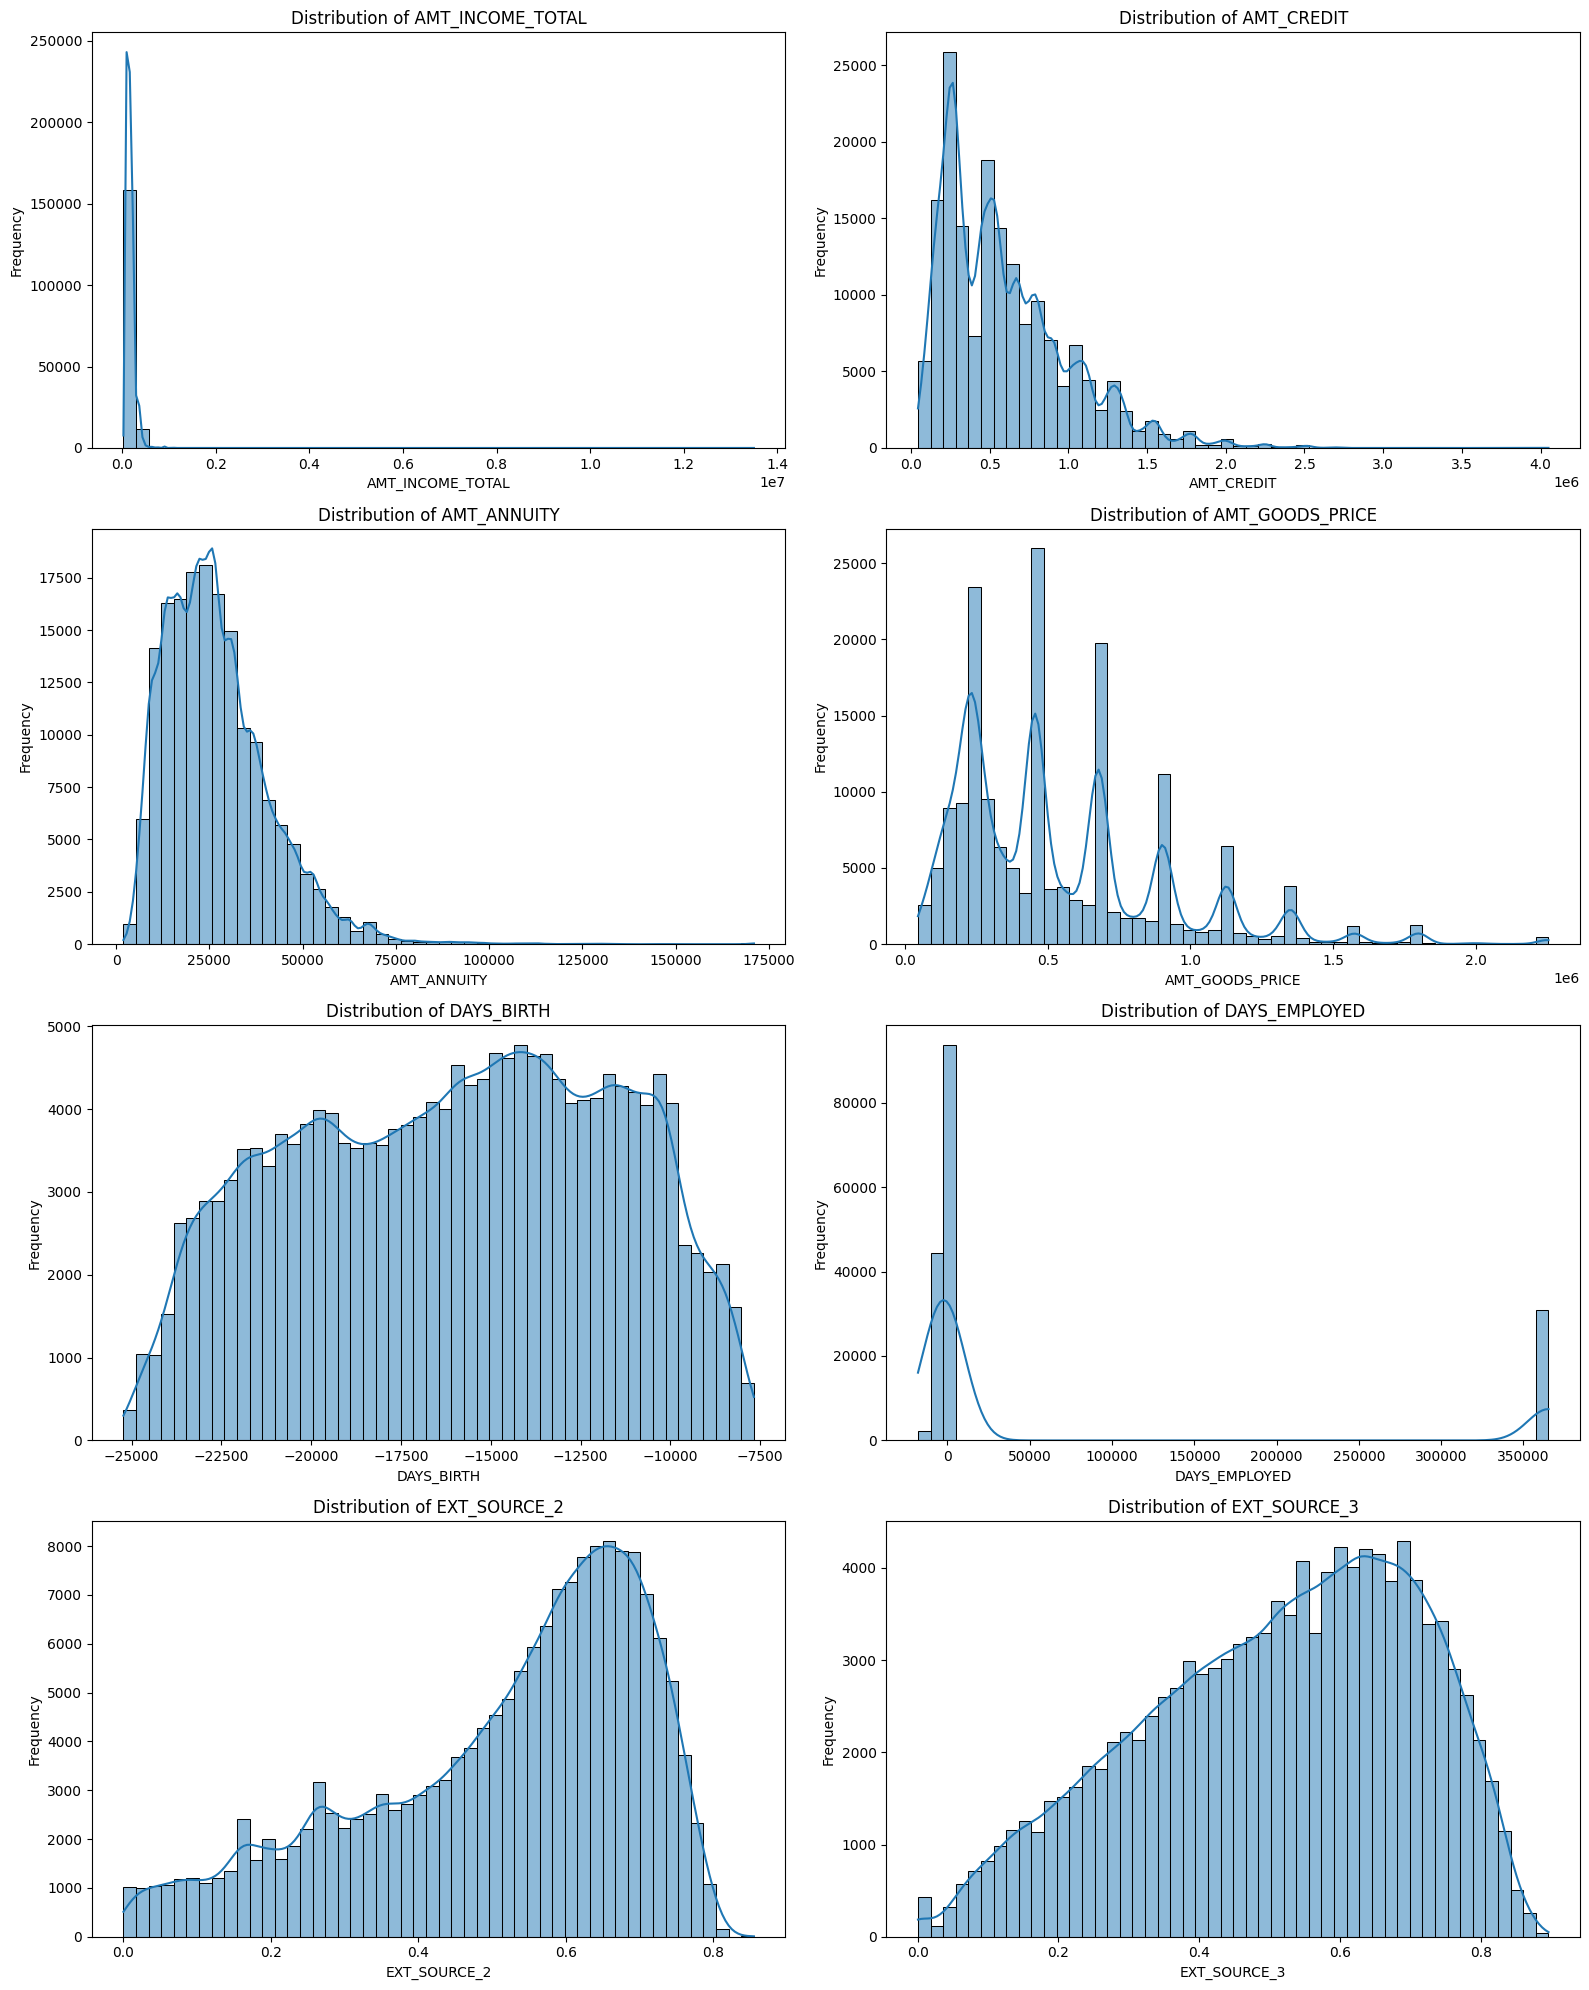

In [ ]:
# STEP 4.4.5
# Numerical Feature Distribution Analysis

# Select important numerical features for initial visualization
selected_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

# Create distribution plots
plt.figure(figsize=(16, 20))

for i, feature in enumerate(selected_features, 1):

    plt.subplot(4, 2, i)

    sns.histplot(
        data=train,
        x=feature,
        kde=True,
        bins=50
    )

    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# STEP 4.4.6
# Numerical Feature Skewness Analysis

# Calculate skewness for numerical features
skewness_values = train[numerical_features].skew()

# Create a summary DataFrame
skewness_summary = pd.DataFrame({
    'Feature': skewness_values.index,
    'Skewness': skewness_values.values
})

# Classify distribution based on skewness
def classify_skewness(value):

    if value > 1:
        return 'Highly Right-Skewed'

    elif value > 0.5:
        return 'Moderately Right-Skewed'

    elif value < -1:
        return 'Highly Left-Skewed'

    elif value < -0.5:
        return 'Moderately Left-Skewed'

    else:
        return 'Approximately Symmetric'

skewness_summary['Distribution_Type'] = (
    skewness_summary['Skewness'].apply(classify_skewness)
)

# Sort by skewness
skewness_summary = skewness_summary.sort_values(
    by='Skewness',
    ascending=False
)

print("NUMERICAL FEATURE SKEWNESS ANALYSIS")

display(skewness_summary)

NUMERICAL FEATURE SKEWNESS ANALYSIS


,Feature,Skewness,Distribution_Type
22,AMT_REQ_CREDIT_BUREAU_QRT,157.338527,Highly Right-Skewed
1,AMT_INCOME_TOTAL,20.118116,Highly Right-Skewed
20,AMT_REQ_CREDIT_BUREAU_HOUR,14.642270,Highly Right-Skewed
21,AMT_REQ_CREDIT_BUREAU_MON,7.673409,Highly Right-Skewed
10,OWN_CAR_AGE,2.740592,Highly Right-Skewed
0,CNT_CHILDREN,1.887244,Highly Right-Skewed
7,DAYS_EMPLOYED,1.660790,Highly Right-Skewed
13,FLAG_WORK_PHONE,1.502178,Highly Right-Skewed
5,REGION_POPULATION_RELATIVE,1.484623,Highly Right-Skewed
3,AMT_ANNUITY,1.441385,Highly Right-Skewed


In [ ]:
# STEP 3.1
# Re-import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [ ]:
# STEP 3.2
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# STEP 3.3
# Define Competition File Paths

competition_path = Path(
    '/content/drive/MyDrive/GCI_World_2026/Competition'
)

input_path = competition_path / 'input'

train_path = input_path / 'train.csv'
test_path = input_path / 'test.csv'
submission_path = input_path / 'sample_submission.csv'

print("Competition Path:", competition_path)
print("Input Path:", input_path)

print("\nTrain File Exists:", train_path.exists())
print("Test File Exists:", test_path.exists())
print("Sample Submission Exists:", submission_path.exists())

Competition Path: /content/drive/MyDrive/GCI_World_2026/Competition
Input Path: /content/drive/MyDrive/GCI_World_2026/Competition/input

Train File Exists: True
Test File Exists: True
Sample Submission Exists: True


In [ ]:
# STEP 3.4
# Reload Competition Datasets

train = pd.read_csv(train_path)

test = pd.read_csv(test_path)

sample_submission = pd.read_csv(submission_path)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [ ]:
# STEP 3.5
# Verify Dataset Shapes

print("TRAIN DATASET:")
print("Shape:", train.shape)

print("\nTEST DATASET:")
print("Shape:", test.shape)

print("\nSAMPLE SUBMISSION:")
print("Shape:", sample_submission.shape)

TRAIN DATASET:
Shape: (171202, 34)

TEST DATASET:
Shape: (61500, 33)

SAMPLE SUBMISSION:
Shape: (61500, 2)


In [ ]:
# STEP 4.5.1
# Categorical Feature Identification

categorical_features = train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col != 'DAYS_EMPLOYED_GROUP'
]

print("CATEGORICAL FEATURE IDENTIFICATION")

print("\nTotal Categorical Features:",
      len(categorical_features))

print("\nCategorical Feature Names:")

for i, feature in enumerate(categorical_features, 1):
    print(f"{i}. {feature}")

CATEGORICAL FEATURE IDENTIFICATION

Total Categorical Features: 8

Categorical Feature Names:
1. NAME_CONTRACT_TYPE
2. CODE_GENDER
3. NAME_INCOME_TYPE
4. NAME_EDUCATION_TYPE
5. NAME_FAMILY_STATUS
6. NAME_HOUSING_TYPE
7. OCCUPATION_TYPE
8. ORGANIZATION_TYPE


In [ ]:
# STEP 4.5.2
# Unique Category Analysis

print("UNIQUE CATEGORY ANALYSIS")

print("\nNumber of Unique Categories in Each Feature:\n")

for feature in categorical_features:

    unique_count = train[feature].nunique()

    print(f"{feature}: {unique_count} unique categories")

UNIQUE CATEGORY ANALYSIS

Number of Unique Categories in Each Feature:

NAME_CONTRACT_TYPE: 2 unique categories
CODE_GENDER: 3 unique categories
NAME_INCOME_TYPE: 8 unique categories
NAME_EDUCATION_TYPE: 5 unique categories
NAME_FAMILY_STATUS: 6 unique categories
NAME_HOUSING_TYPE: 6 unique categories
OCCUPATION_TYPE: 19 unique categories
ORGANIZATION_TYPE: 58 unique categories


In [ ]:
# STEP 4.5.3
# Categorical Feature Frequency Analysis

print("CATEGORICAL FEATURE FREQUENCY ANALYSIS")

for feature in categorical_features:

    print("\n" + "=" * 60)
    print(f"FEATURE: {feature}")
    print("=" * 60)

    # Count each category, including missing values
    category_counts = train[feature].value_counts(dropna=False)

    # Calculate percentage of each category
    category_percentages = (
        train[feature].value_counts(dropna=False, normalize=True) * 100
    )

    # Combine counts and percentages
    frequency_table = pd.DataFrame({
        "Customer_Count": category_counts,
        "Percentage": category_percentages
    })

    print(frequency_table.round(2))

CATEGORICAL FEATURE FREQUENCY ANALYSIS

FEATURE: NAME_CONTRACT_TYPE
                    Customer_Count  Percentage
NAME_CONTRACT_TYPE                            
Cash loans                  154988       90.53
Revolving loans              16214        9.47

FEATURE: CODE_GENDER
             Customer_Count  Percentage
CODE_GENDER                            
F                    112549       65.74
M                     58649       34.26
XNA                       4        0.00

FEATURE: NAME_INCOME_TYPE
                      Customer_Count  Percentage
NAME_INCOME_TYPE                                
Working                        88268       51.56
Commercial associate           40007       23.37
Pensioner                      30895       18.05
State servant                  12007        7.01
Unemployed                        10        0.01
Student                            9        0.01
Businessman                        3        0.00
Maternity leave                    3        0.00

FEAT

In [ ]:
# STEP 4.5.4
# Categorical Missing Value Analysis

print("CATEGORICAL MISSING VALUE ANALYSIS")

# Create an empty list to store results
missing_results = []

# Analyze categorical features in train and test datasets
for feature in categorical_features:

    # Train dataset analysis
    train_total = len(train)
    train_missing = train[feature].isnull().sum()
    train_missing_pct = (train_missing / train_total) * 100
    train_non_missing = train_total - train_missing

    # Test dataset analysis
    test_total = len(test)
    test_missing = test[feature].isnull().sum()
    test_missing_pct = (test_missing / test_total) * 100
    test_non_missing = test_total - test_missing

    # Store results
    missing_results.append({
        "Feature": feature,
        "Train_Missing_Count": train_missing,
        "Train_Missing_Percentage": train_missing_pct,
        "Train_Non_Missing": train_non_missing,
        "Test_Missing_Count": test_missing,
        "Test_Missing_Percentage": test_missing_pct,
        "Test_Non_Missing": test_non_missing
    })

# Create summary DataFrame
categorical_missing_summary = pd.DataFrame(missing_results)

# Display results
print("\nCATEGORICAL MISSING VALUE SUMMARY:\n")

print(categorical_missing_summary.round(2).to_string(index=False))

CATEGORICAL MISSING VALUE ANALYSIS

CATEGORICAL MISSING VALUE SUMMARY:

            Feature  Train_Missing_Count  Train_Missing_Percentage  Train_Non_Missing  Test_Missing_Count  Test_Missing_Percentage  Test_Non_Missing
 NAME_CONTRACT_TYPE                    0                       0.0             171202                   0                      0.0             61500
        CODE_GENDER                    0                       0.0             171202                   0                      0.0             61500
   NAME_INCOME_TYPE                    0                       0.0             171202                   0                      0.0             61500
NAME_EDUCATION_TYPE                    0                       0.0             171202                   0                      0.0             61500
 NAME_FAMILY_STATUS                    0                       0.0             171202                   0                      0.0             61500
  NAME_HOUSING_TYPE               

In [ ]:
# STEP 4.5.5
# Rare Category Investigation

print("RARE CATEGORY INVESTIGATION")

# Define rare category threshold
rare_threshold = 0.1

# Store rare category results
rare_category_results = []

# Analyze each categorical feature
for feature in categorical_features:

    # Calculate category percentages
    category_percentages = (
        train[feature].value_counts(normalize=True) * 100
    )

    # Identify rare categories
    rare_categories = category_percentages[
        category_percentages < rare_threshold
    ]

    print("\n" + "=" * 60)
    print(f"FEATURE: {feature}")
    print("=" * 60)

    if len(rare_categories) > 0:

        for category, percentage in rare_categories.items():

            count = train[feature].value_counts()[category]

            print(
                f"{category}: {count} customers "
                f"({percentage:.4f}%)"
            )

            rare_category_results.append({
                "Feature": feature,
                "Category": category,
                "Customer_Count": count,
                "Percentage": percentage
            })

    else:

        print("No rare categories found.")

# Create summary DataFrame
rare_category_summary = pd.DataFrame(rare_category_results)

print("\n" + "=" * 60)
print("OVERALL RARE CATEGORY SUMMARY")
print("=" * 60)

if not rare_category_summary.empty:

    print(
        rare_category_summary.round(4).to_string(index=False)
    )

else:

    print("No rare categories found in the dataset.")

RARE CATEGORY INVESTIGATION

FEATURE: NAME_CONTRACT_TYPE
No rare categories found.

FEATURE: CODE_GENDER
XNA: 4 customers (0.0023%)

FEATURE: NAME_INCOME_TYPE
Unemployed: 10 customers (0.0058%)
Student: 9 customers (0.0053%)
Businessman: 3 customers (0.0018%)
Maternity leave: 3 customers (0.0018%)

FEATURE: NAME_EDUCATION_TYPE
Academic degree: 101 customers (0.0590%)

FEATURE: NAME_FAMILY_STATUS
Unknown: 2 customers (0.0012%)

FEATURE: NAME_HOUSING_TYPE
No rare categories found.

FEATURE: OCCUPATION_TYPE
No rare categories found.

FEATURE: ORGANIZATION_TYPE
Cleaning: 146 customers (0.0853%)
Transport: type 1: 100 customers (0.0584%)
Industry: type 10: 63 customers (0.0368%)
Industry: type 6: 60 customers (0.0350%)
Religion: 53 customers (0.0310%)
Industry: type 13: 37 customers (0.0216%)
Trade: type 4: 37 customers (0.0216%)
Trade: type 5: 26 customers (0.0152%)
Industry: type 8: 8 customers (0.0047%)

OVERALL RARE CATEGORY SUMMARY
            Feature          Category  Customer_Count 

In [ ]:
# STEP 4.5.6
# Categorical Feature Summary

categorical_summary = []

for feature in categorical_features:

    # Calculate category frequencies
    category_counts = train[feature].value_counts()

    # Calculate category percentages
    category_percentages = (
        train[feature].value_counts(normalize=True) * 100
    )

    # Identify most and least frequent categories
    most_frequent_category = category_counts.idxmax()
    least_frequent_category = category_counts.idxmin()

    # Count rare categories
    rare_category_count = (
        category_percentages < 0.1
    ).sum()

    # Store summary
    categorical_summary.append({

        "Feature": feature,

        "Unique_Categories": train[feature].nunique(),

        "Most_Frequent_Category": most_frequent_category,

        "Most_Frequent_Count": category_counts.max(),

        "Least_Frequent_Category": least_frequent_category,

        "Least_Frequent_Count": category_counts.min(),

        "Rare_Category_Count": rare_category_count,

        "Missing_Values": train[feature].isnull().sum()

    })


# Create summary DataFrame
categorical_summary_df = pd.DataFrame(categorical_summary)


# Display results
print("CATEGORICAL FEATURE SUMMARY")
print("=" * 90)

print(
    categorical_summary_df.to_string(index=False)
)

CATEGORICAL FEATURE SUMMARY
            Feature  Unique_Categories        Most_Frequent_Category  Most_Frequent_Count Least_Frequent_Category  Least_Frequent_Count  Rare_Category_Count  Missing_Values
 NAME_CONTRACT_TYPE                  2                    Cash loans               154988         Revolving loans                 16214                    0               0
        CODE_GENDER                  3                             F               112549                     XNA                     4                    1               0
   NAME_INCOME_TYPE                  8                       Working                88268             Businessman                     3                    4               0
NAME_EDUCATION_TYPE                  5 Secondary / secondary special               121612         Academic degree                   101                    1               0
 NAME_FAMILY_STATUS                  6                       Married               109323                 U

In [ ]:
# STEP 4.6.1
# Continuous Numerical Feature Outlier Detection

continuous_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'REGION_POPULATION_RELATIVE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_REGISTRATION',
    'DAYS_ID_PUBLISH',
    'OWN_CAR_AGE',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'DAYS_LAST_PHONE_CHANGE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

# Store outlier analysis results
outlier_results = []

print("CONTINUOUS FEATURE OUTLIER INVESTIGATION")
print("=" * 80)

for feature in continuous_features:

    # Create a temporary series
    values = train[feature].copy()

    # Handle special DAYS_EMPLOYED value
    if feature == 'DAYS_EMPLOYED':

        special_value_count = (values == 365243).sum()

        values = values.replace(365243, np.nan)

    else:

        special_value_count = 0

    # Calculate quartiles
    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    # Calculate IQR
    IQR = Q3 - Q1

    # Calculate boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify potential outliers
    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    # Calculate percentage
    valid_count = values.notna().sum()

    outlier_percentage = (
        outlier_count / valid_count
    ) * 100 if valid_count > 0 else 0

    # Store results
    outlier_results.append({

        'Feature': feature,

        'Q1': Q1,

        'Q3': Q3,

        'IQR': IQR,

        'Lower_Bound': lower_bound,

        'Upper_Bound': upper_bound,

        'Outlier_Count': outlier_count,

        'Outlier_Percentage': outlier_percentage,

        'Special_Value_Count': special_value_count

    })


# Create summary DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Display results
print(
    outlier_summary.round(4).to_string(index=False)
)

CONTINUOUS FEATURE OUTLIER INVESTIGATION
                   Feature          Q1          Q3         IQR  Lower_Bound  Upper_Bound  Outlier_Count  Outlier_Percentage  Special_Value_Count
          AMT_INCOME_TOTAL 112500.0000 202500.0000  90000.0000  -22500.0000  337500.0000           7784              4.5467                    0
                AMT_CREDIT 270000.0000 808650.0000 538650.0000 -537975.0000 1616625.0000           3630              2.1203                    0
               AMT_ANNUITY  16546.5000  34600.5000  18054.0000  -10534.5000   61681.5000           4179              2.4410                    0
           AMT_GOODS_PRICE 238500.0000 679500.0000 441000.0000 -423000.0000 1341000.0000           8197              4.7879                    0
REGION_POPULATION_RELATIVE      0.0100      0.0287      0.0187      -0.0180       0.0566           4624              2.7009                    0
                DAYS_BIRTH -19686.0000 -12420.0000   7266.0000  -30585.0000   -1521.0000 

In [ ]:
# STEP 4.6.2
# Extreme Value Investigation

investigation_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_EMPLOYED',
    'OWN_CAR_AGE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

extreme_results = []

print("EXTREME VALUE INVESTIGATION")
print("=" * 100)

for feature in investigation_features:

    values = train[feature].copy()

    # Separate special DAYS_EMPLOYED value
    if feature == 'DAYS_EMPLOYED':

        special_count = (values == 365243).sum()

        values = values.replace(365243, np.nan)

    else:

        special_count = 0

    # Calculate distribution statistics
    extreme_results.append({

        'Feature': feature,

        'Minimum': values.min(),

        'Median': values.median(),

        '95th_Percentile': values.quantile(0.95),

        '99th_Percentile': values.quantile(0.99),

        'Maximum': values.max(),

        'Missing_Count': values.isna().sum(),

        'Special_Value_Count': special_count

    })


# Create summary table
extreme_summary = pd.DataFrame(extreme_results)

print(
    extreme_summary.round(4).to_string(index=False)
)

EXTREME VALUE INVESTIGATION
                   Feature  Minimum   Median  95th_Percentile  99th_Percentile    Maximum  Missing_Count  Special_Value_Count
          AMT_INCOME_TOTAL  26100.0 146250.0         337500.0       463500.000 13500000.0              0                    0
                AMT_CREDIT  45000.0 514602.0        1350000.0      1868801.760  4050000.0              0                    0
               AMT_ANNUITY   1980.0  24916.5          53329.5        70132.365   170986.5              0                    0
           AMT_GOODS_PRICE  45000.0 450000.0        1305000.0      1800000.000  2254500.0              0                    0
             DAYS_EMPLOYED -17912.0  -1650.0           -206.0         -111.000       -1.0          30898                30898
               OWN_CAR_AGE      0.0      9.0             30.0           64.000       91.0         112992                    0
AMT_REQ_CREDIT_BUREAU_HOUR      0.0      0.0              0.0            0.000        4.0 

In [ ]:
# STEP 4.6.3
# Extreme Value Frequency Investigation

print("EXTREME VALUE FREQUENCY ANALYSIS")
print("=" * 80)

# 1. Credit Bureau QRT
print("\n1. AMT_REQ_CREDIT_BUREAU_QRT")

qrt = train['AMT_REQ_CREDIT_BUREAU_QRT']

print("Values greater than 10:", (qrt > 10).sum())
print("Values greater than 50:", (qrt > 50).sum())
print("Maximum value frequency:")
print(qrt.value_counts().head(10))


# 2. Income
print("\n2. AMT_INCOME_TOTAL")

income = train['AMT_INCOME_TOTAL']

print("Income above 1 million:", (income > 1000000).sum())
print("Income above 5 million:", (income > 5000000).sum())


# 3. Car Age
print("\n3. OWN_CAR_AGE")

car_age = train['OWN_CAR_AGE']

print("Car age above 30:", (car_age > 30).sum())
print("Car age above 50:", (car_age > 50).sum())


# 4. Employment duration
print("\n4. DAYS_EMPLOYED")

employment = train['DAYS_EMPLOYED']

print("Values below -10000:", (employment < -10000).sum())
print("Values between -10000 and -5000:",
      ((employment >= -10000) & (employment < -5000)).sum())

print("Special value 365243:", (employment == 365243).sum())

EXTREME VALUE FREQUENCY ANALYSIS

1. AMT_REQ_CREDIT_BUREAU_QRT
Values greater than 10: 2
Values greater than 50: 1
Maximum value frequency:
AMT_REQ_CREDIT_BUREAU_QRT
0.0     119813
1.0      18906
2.0       8077
3.0        961
4.0        267
5.0         38
6.0         17
7.0          3
8.0          2
19.0         1
Name: count, dtype: int64

2. AMT_INCOME_TOTAL
Income above 1 million: 139
Income above 5 million: 3

3. OWN_CAR_AGE
Car age above 30: 2730
Car age above 50: 1833

4. DAYS_EMPLOYED
Values below -10000: 2486
Values between -10000 and -5000: 13918
Special value 365243: 30898


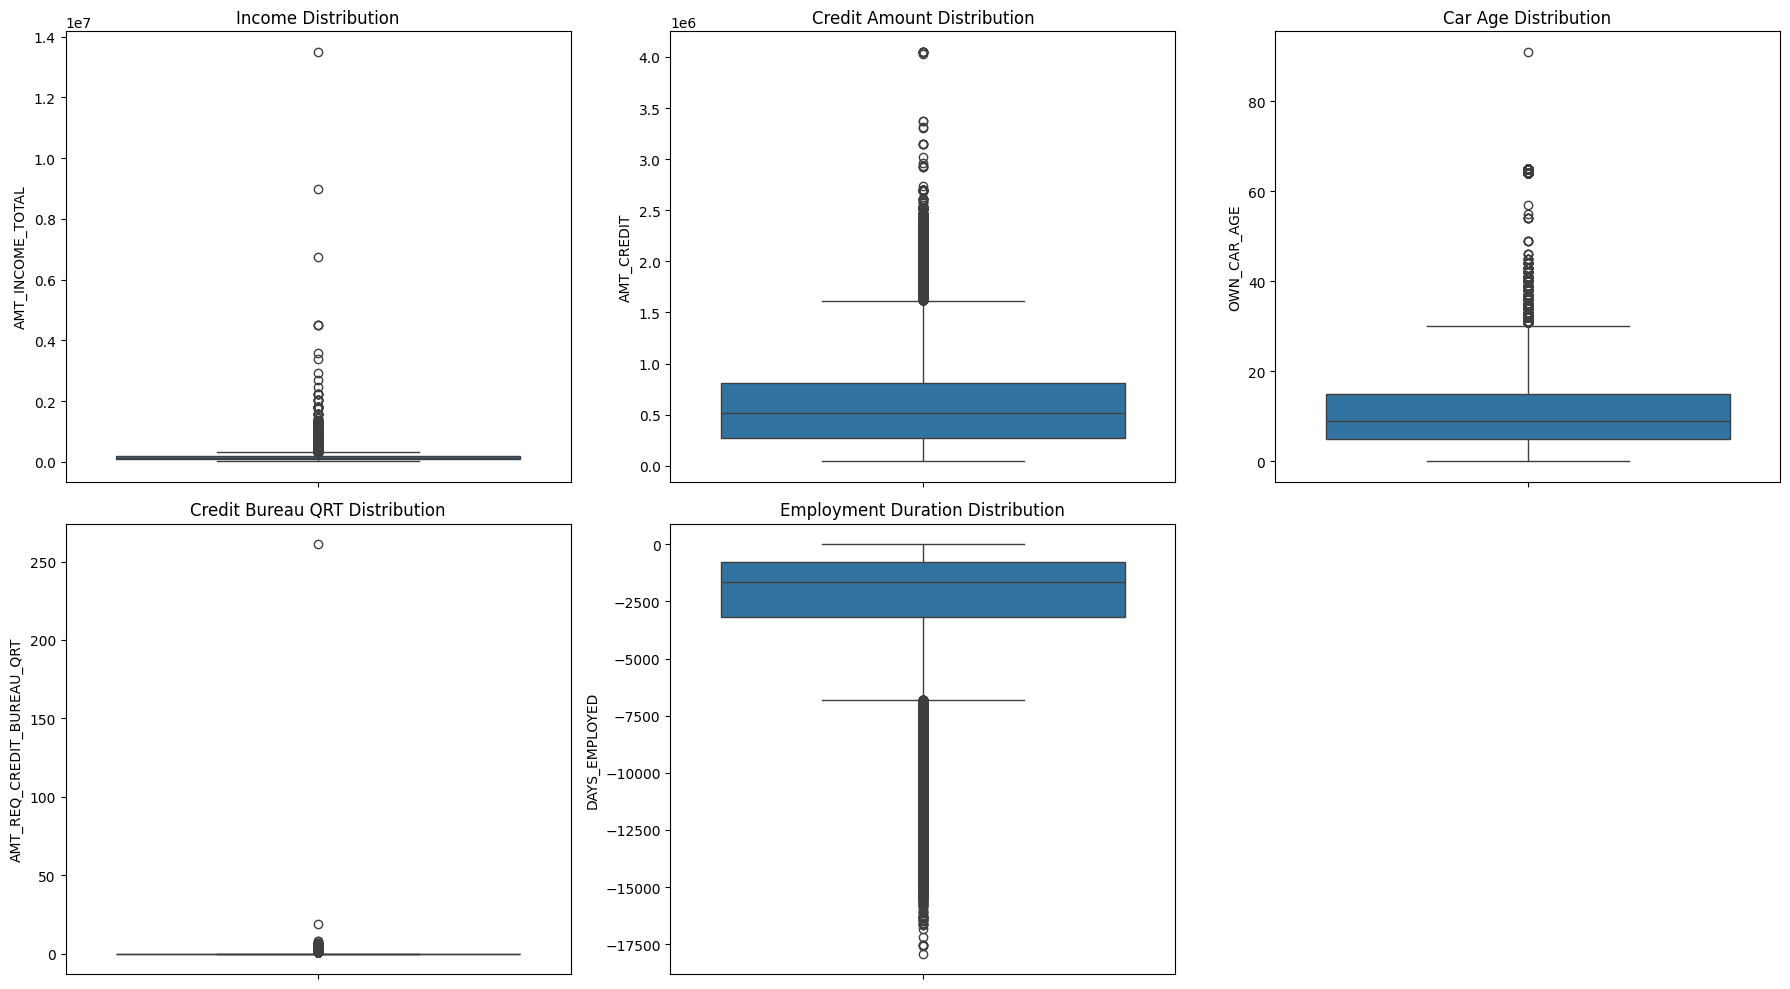

In [ ]:
# STEP 4.6.4
# Outlier Visualization Using Boxplots

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. AMT_INCOME_TOTAL
sns.boxplot(y=train['AMT_INCOME_TOTAL'], ax=axes[0, 0])
axes[0, 0].set_title('Income Distribution')

# 2. AMT_CREDIT
sns.boxplot(y=train['AMT_CREDIT'], ax=axes[0, 1])
axes[0, 1].set_title('Credit Amount Distribution')

# 3. OWN_CAR_AGE
sns.boxplot(y=train['OWN_CAR_AGE'], ax=axes[0, 2])
axes[0, 2].set_title('Car Age Distribution')

# 4. AMT_REQ_CREDIT_BUREAU_QRT
sns.boxplot(y=train['AMT_REQ_CREDIT_BUREAU_QRT'], ax=axes[1, 0])
axes[1, 0].set_title('Credit Bureau QRT Distribution')

# 5. DAYS_EMPLOYED
employment_clean = train['DAYS_EMPLOYED'].replace(365243, np.nan)

sns.boxplot(y=employment_clean, ax=axes[1, 1])
axes[1, 1].set_title('Employment Duration Distribution')

# Remove unused subplot
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

In [ ]:
# STEP 4.6.5
# Discrete, Binary and Ordinal Feature Investigation

discrete_features = [
    'CNT_CHILDREN',
    'CNT_FAM_MEMBERS',
    'REGION_RATING_CLIENT',
    'FLAG_MOBIL',
    'FLAG_EMP_PHONE',
    'FLAG_WORK_PHONE',
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

print("DISCRETE AND BINARY FEATURE ANALYSIS")
print("=" * 80)

for feature in discrete_features:

    print(f"\nFeature: {feature}")
    print("-" * 50)

    print("Unique Values:", train[feature].nunique())
    print("Missing Values:", train[feature].isnull().sum())

    print("\nValue Frequencies:")
    print(train[feature].value_counts(dropna=False).sort_index().head(15))

DISCRETE AND BINARY FEATURE ANALYSIS

Feature: CNT_CHILDREN
--------------------------------------------------
Unique Values: 13
Missing Values: 0

Value Frequencies:
CNT_CHILDREN
0     119950
1      33975
2      14932
3       2049
4        230
5         40
6         13
7          5
8          2
9          1
10         2
12         1
14         2
Name: count, dtype: int64

Feature: CNT_FAM_MEMBERS
--------------------------------------------------
Unique Values: 15
Missing Values: 2

Value Frequencies:
CNT_FAM_MEMBERS
1.0     37766
2.0     88165
3.0     29284
4.0     13801
5.0      1903
6.0       220
7.0        36
8.0        13
9.0         4
10.0        2
11.0        1
12.0        2
14.0        1
15.0        1
16.0        1
Name: count, dtype: int64

Feature: REGION_RATING_CLIENT
--------------------------------------------------
Unique Values: 3
Missing Values: 0

Value Frequencies:
REGION_RATING_CLIENT
1     17801
2    126402
3     26999
Name: count, dtype: int64

Feature: FLAG_MOBIL

In [ ]:
# STEP 4.6.6
# Logical Consistency Investigation

print("LOGICAL CONSISTENCY ANALYSIS")
print("=" * 80)

# 1. Compare children and family members

valid_data = train[
    ['CNT_CHILDREN', 'CNT_FAM_MEMBERS']
].dropna()

inconsistent_count = (
    valid_data['CNT_CHILDREN'] >= valid_data['CNT_FAM_MEMBERS']
).sum()

print("\n1. FAMILY SIZE CONSISTENCY")

print("Valid observations:", len(valid_data))
print("Potentially inconsistent observations:", inconsistent_count)

print("\nExamples of potentially inconsistent records:")

print(
    valid_data[
        valid_data['CNT_CHILDREN'] >= valid_data['CNT_FAM_MEMBERS']
    ].head(10)
)


# 2. FLAG_MOBIL analysis

print("\n2. FLAG_MOBIL ANALYSIS")

print("Value proportions:")

print(
    train['FLAG_MOBIL'].value_counts(normalize=True) * 100
)

print(
    "\nNumber of unique values:",
    train['FLAG_MOBIL'].nunique()
)

LOGICAL CONSISTENCY ANALYSIS

1. FAMILY SIZE CONSISTENCY
Valid observations: 171200
Potentially inconsistent observations: 0

Examples of potentially inconsistent records:
Empty DataFrame
Columns: [CNT_CHILDREN, CNT_FAM_MEMBERS]
Index: []

2. FLAG_MOBIL ANALYSIS
Value proportions:
FLAG_MOBIL
1    99.999416
0     0.000584
Name: proportion, dtype: float64

Number of unique values: 2


TARGET DISTRIBUTION
        Customer_Count  Percentage
TARGET                            
0               157381    91.92708
1                13821     8.07292


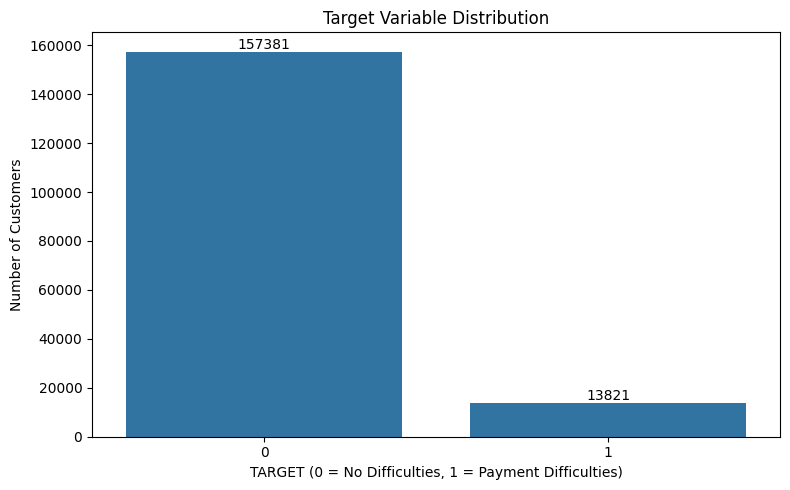

In [ ]:
# STEP 5.1
# Target Distribution Visualization

# 1. Calculate target counts
target_counts = train['TARGET'].value_counts().sort_index()

# 2. Calculate target percentages
target_percentages = train['TARGET'].value_counts(
    normalize=True
).sort_index() * 100

# 3. Display target distribution
print("TARGET DISTRIBUTION")
print("=" * 60)

target_summary = pd.DataFrame({
    'Customer_Count': target_counts,
    'Percentage': target_percentages
})

print(target_summary)

# 4. Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train,
    x='TARGET'
)

plt.title('Target Variable Distribution')
plt.xlabel('TARGET (0 = No Difficulties, 1 = Payment Difficulties)')
plt.ylabel('Number of Customers')

# 5. Add count and percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

In [ ]:
# STEP 5.2.1
# Numerical Features vs TARGET
# Group-wise Statistical Comparison

numerical_features = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3'
]

# Create a temporary copy for analysis
eda_data = train[numerical_features + ['TARGET']].copy()

# Handle DAYS_EMPLOYED special value for this comparison only
eda_data['DAYS_EMPLOYED'] = eda_data[
    'DAYS_EMPLOYED'
].replace(365243, np.nan)

# Calculate statistics for each target group
comparison = eda_data.groupby('TARGET')[numerical_features].agg(
    ['mean', 'median']
)

print("NUMERICAL FEATURES VS TARGET")
print("=" * 100)

print(comparison.T)

NUMERICAL FEATURES VS TARGET
TARGET                               0              1
AMT_INCOME_TOTAL mean    169058.816794  160541.413610
                 median  148500.000000  135000.000000
AMT_CREDIT       mean    603036.026563  554643.162796
                 median  518562.000000  495000.000000
AMT_ANNUITY      mean     27182.692315   26406.933796
                 median   24894.000000   25204.500000
AMT_GOODS_PRICE  mean    542648.129990  485776.100534
                 median  450000.000000  450000.000000
DAYS_BIRTH       mean    -16148.201136  -14874.057015
                 median  -15901.000000  -14284.000000
DAYS_EMPLOYED    mean     -2441.527891   -1829.888102
                 median   -1692.000000   -1234.000000
EXT_SOURCE_1     mean         0.510937       0.387465
                 median       0.517352       0.361529
EXT_SOURCE_2     mean         0.523723       0.409587
                 median       0.574311       0.438320
EXT_SOURCE_3     mean         0.521213       0.390974

PHASE 06 — OFFICIAL BASELINE REPRODUCTION

In [ ]:
import pandas as pd

In [ ]:
# PHASE 06.1 — Reload Original Dataset

train_raw = pd.read_csv(competition_path / "input" / "train.csv")

test_raw = pd.read_csv(competition_path / "input" / "test.csv")

sample_sub = pd.read_csv(competition_path / "input" / "sample_submission.csv")


# Verify dataset dimensions

print("ORIGINAL DATASET VERIFICATION")
print("-" * 45)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Sample submission shape:", sample_sub.shape)

print("\nTarget distribution:")
print(train_raw["TARGET"].value_counts())

print("\nDataset reload completed.")

NameError: name 'competition_path' is not defined

In [1]:
# ============================================================
# PHASE 06.1 — COMPLETE ENVIRONMENT SETUP
# GCI WORLD 2026 IN-CLASS COMPETITION
# ============================================================


# 1. Import Libraries

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

warnings.filterwarnings('ignore')


# 2. Connect Google Drive

from google.colab import drive

drive.mount('/content/drive')


# 3. Define Competition Folder Path

competition_path = Path(
    '/content/drive/MyDrive/GCI_World_2026/Competition'
)


# 4. Define Input Folder Path

input_path = competition_path / 'input'


# 5. Define Dataset File Paths

train_path = input_path / 'train.csv'

test_path = input_path / 'test.csv'

submission_path = input_path / 'sample_submission.csv'


# 6. Verify All Required Files

print("=" * 60)
print("GCI WORLD 2026 — ENVIRONMENT VERIFICATION")
print("=" * 60)

print("\nLIBRARY STATUS")
print("-" * 40)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Libraries imported successfully.")


print("\nGOOGLE DRIVE STATUS")
print("-" * 40)

print("Drive connected:", os.path.exists('/content/drive/MyDrive'))


print("\nCOMPETITION DIRECTORY")
print("-" * 40)

print("Competition folder:", competition_path)
print("Folder exists:", competition_path.exists())

print("\nINPUT FILE VERIFICATION")
print("-" * 40)

print("Train file exists:", train_path.exists())
print("Test file exists:", test_path.exists())
print("Sample submission exists:", submission_path.exists())


# 7. Final Setup Status

if (
    competition_path.exists()
    and train_path.exists()
    and test_path.exists()
    and submission_path.exists()
):

    print("\nSUCCESS: ENVIRONMENT SETUP COMPLETED!")

else:

    print("\nERROR: SOME FILES OR FOLDERS COULD NOT BE FOUND.")

print("=" * 60)

Mounted at /content/drive
GCI WORLD 2026 — ENVIRONMENT VERIFICATION

LIBRARY STATUS
----------------------------------------
NumPy: 2.4.6
Pandas: 2.2.3
Libraries imported successfully.

GOOGLE DRIVE STATUS
----------------------------------------
Drive connected: True

COMPETITION DIRECTORY
----------------------------------------
Competition folder: /content/drive/MyDrive/GCI_World_2026/Competition
Folder exists: True

INPUT FILE VERIFICATION
----------------------------------------
Train file exists: True
Test file exists: True
Sample submission exists: True

SUCCESS: ENVIRONMENT SETUP COMPLETED!


In [2]:
# ============================================================
# PHASE 06.2 — LOAD ORIGINAL DATASETS
# ============================================================

# Load training dataset
train_raw = pd.read_csv(train_path)

# Load testing dataset
test_raw = pd.read_csv(test_path)

# Load sample submission
sample_sub = pd.read_csv(submission_path)


# ============================================================
# DATASET VERIFICATION
# ============================================================

print("=" * 60)
print("DATASET LOADING AND VERIFICATION")
print("=" * 60)


# Check dataset dimensions

print("\n1. DATASET SHAPES")
print("-" * 40)

print("Training dataset:", train_raw.shape)
print("Testing dataset:", test_raw.shape)
print("Sample submission:", sample_sub.shape)


# Check training target distribution

print("\n2. TARGET DISTRIBUTION")
print("-" * 40)

print(train_raw["TARGET"].value_counts())


# Check submission columns

print("\n3. SAMPLE SUBMISSION COLUMNS")
print("-" * 40)

print(sample_sub.columns.tolist())


# Check first five rows

print("\n4. TRAINING DATA PREVIEW")
print("-" * 40)

display(train_raw.head())


print("\n5. TEST DATA PREVIEW")
print("-" * 40)

display(test_raw.head())


print("\nDATASET LOADING COMPLETED!")
print("=" * 60)

DATASET LOADING AND VERIFICATION

1. DATASET SHAPES
----------------------------------------
Training dataset: (171202, 34)
Testing dataset: (61500, 33)
Sample submission: (61500, 2)

2. TARGET DISTRIBUTION
----------------------------------------
TARGET
0    157381
1     13821
Name: count, dtype: int64

3. SAMPLE SUBMISSION COLUMNS
----------------------------------------
['SK_ID_CURR', 'TARGET']

4. TRAINING DATA PREVIEW
----------------------------------------


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1



5. TEST DATA PREVIEW
----------------------------------------


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0



DATASET LOADING COMPLETED!


In [3]:
# ============================================================
# PHASE 06.3 — OFFICIAL FIVE-FEATURE SELECTION
# ============================================================

# Official tutorial's selected features

use_features = [
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_2",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE"
]


# Create separate feature datasets

X = train_raw[use_features].copy()

X_test = test_raw[use_features].copy()

y = train_raw["TARGET"].copy()


# ============================================================
# FEATURE SELECTION VERIFICATION
# ============================================================

print("=" * 60)
print("OFFICIAL FIVE-FEATURE SELECTION")
print("=" * 60)

print("\n1. SELECTED FEATURES")
print("-" * 40)

for i, feature in enumerate(use_features, start=1):
    print(f"{i}. {feature}")


print("\n2. DATASET SHAPES")
print("-" * 40)

print("X (Training features):", X.shape)
print("y (Target variable):", y.shape)
print("X_test (Testing features):", X_test.shape)


print("\n3. TRAINING FEATURE PREVIEW")
print("-" * 40)

display(X.head())


print("\n4. TESTING FEATURE PREVIEW")
print("-" * 40)

display(X_test.head())


print("\n5. TARGET PREVIEW")
print("-" * 40)

display(y.head())


print("\nFEATURE SELECTION COMPLETED!")
print("=" * 60)

OFFICIAL FIVE-FEATURE SELECTION

1. SELECTED FEATURES
----------------------------------------
1. NAME_CONTRACT_TYPE
2. AMT_INCOME_TOTAL
3. EXT_SOURCE_2
4. OWN_CAR_AGE
5. ORGANIZATION_TYPE

2. DATASET SHAPES
----------------------------------------
X (Training features): (171202, 5)
y (Target variable): (171202,)
X_test (Testing features): (61500, 5)

3. TRAINING FEATURE PREVIEW
----------------------------------------


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE
0,Cash loans,112500.0,0.372591,NaN,School
1,Cash loans,225000.0,0.449567,NaN,XNA
2,Cash loans,54000.0,0.569503,NaN,Postal
3,Cash loans,67500.0,0.105235,NaN,XNA
4,Cash loans,157500.0,0.202490,NaN,Business Entity Type 3



4. TESTING FEATURE PREVIEW
----------------------------------------


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_2,OWN_CAR_AGE,ORGANIZATION_TYPE
0,Cash loans,144000.0,0.720416,NaN,Kindergarten
1,Cash loans,103500.0,0.287306,NaN,School
2,Cash loans,180000.0,0.352456,NaN,Trade: type 7
3,Revolving loans,225000.0,0.470384,NaN,Business Entity Type 3
4,Cash loans,144000.0,0.373133,14.0,Business Entity Type 3



5. TARGET PREVIEW
----------------------------------------


,TARGET
0,0
1,0
2,0
3,0
4,1



FEATURE SELECTION COMPLETED!


In [4]:
# ============================================================
# PHASE 06.4 — TRAIN-VALIDATION SPLIT
# ============================================================

from sklearn.model_selection import train_test_split


# Split the dataset into training and validation subsets

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


# ============================================================
# SPLIT VERIFICATION
# ============================================================

print("=" * 60)
print("TRAIN-VALIDATION SPLIT VERIFICATION")
print("=" * 60)


# Check dataset dimensions

print("\n1. DATASET SHAPES")
print("-" * 40)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)


# Check target distribution

print("\n2. TRAINING TARGET DISTRIBUTION (%)")
print("-" * 40)

print((y_train.value_counts(normalize=True) * 100).round(2))


print("\n3. VALIDATION TARGET DISTRIBUTION (%)")
print("-" * 40)

print((y_valid.value_counts(normalize=True) * 100).round(2))


# Verify total observations

print("\n4. TOTAL OBSERVATIONS")
print("-" * 40)

print("Original dataset:", len(X))
print("Training subset:", len(X_train))
print("Validation subset:", len(X_valid))

print("Total after splitting:", len(X_train) + len(X_valid))


print("\nTRAIN-VALIDATION SPLIT COMPLETED!")
print("=" * 60)

TRAIN-VALIDATION SPLIT VERIFICATION

1. DATASET SHAPES
----------------------------------------
X_train: (119841, 5)
X_valid: (51361, 5)
y_train: (119841,)
y_valid: (51361,)

2. TRAINING TARGET DISTRIBUTION (%)
----------------------------------------
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

3. VALIDATION TARGET DISTRIBUTION (%)
----------------------------------------
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

4. TOTAL OBSERVATIONS
----------------------------------------
Original dataset: 171202
Training subset: 119841
Validation subset: 51361
Total after splitting: 171202

TRAIN-VALIDATION SPLIT COMPLETED!


In [5]:
# ============================================================
# PHASE 06.5.1 — PREPROCESSING DATA INSPECTION
# ============================================================

print("=" * 60)
print("PREPROCESSING DATA INSPECTION")
print("=" * 60)


# 1. Check missing values in training features

print("\n1. TRAINING FEATURE MISSING VALUES")
print("-" * 40)

missing_train = X_train.isnull().sum()

missing_train_percent = (
    X_train.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_train,
    "Missing Percentage (%)": missing_train_percent
})

display(missing_summary)


# 2. Check missing values in validation features

print("\n2. VALIDATION FEATURE MISSING VALUES")
print("-" * 40)

display(X_valid.isnull().sum())


# 3. Check data types

print("\n3. FEATURE DATA TYPES")
print("-" * 40)

print(X_train.dtypes)


# 4. Check categorical feature values

print("\n4. CATEGORICAL FEATURE CATEGORIES")
print("-" * 40)

for feature in ["NAME_CONTRACT_TYPE", "ORGANIZATION_TYPE"]:

    print(f"\n{feature}")

    print("Unique categories:", X_train[feature].nunique())

    print("Top 10 categories:")

    print(X_train[feature].value_counts().head(10))


print("\nPREPROCESSING INSPECTION COMPLETED!")
print("=" * 60)

PREPROCESSING DATA INSPECTION

1. TRAINING FEATURE MISSING VALUES
----------------------------------------


,Missing Count,Missing Percentage (%)
NAME_CONTRACT_TYPE,0,0.0
AMT_INCOME_TOTAL,0,0.0
EXT_SOURCE_2,245,0.2
OWN_CAR_AGE,79096,66.0
ORGANIZATION_TYPE,0,0.0



2. VALIDATION FEATURE MISSING VALUES
----------------------------------------


,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_2,124
OWN_CAR_AGE,33896
ORGANIZATION_TYPE,0



3. FEATURE DATA TYPES
----------------------------------------
NAME_CONTRACT_TYPE     object
AMT_INCOME_TOTAL      float64
EXT_SOURCE_2          float64
OWN_CAR_AGE           float64
ORGANIZATION_TYPE      object
dtype: object

4. CATEGORICAL FEATURE CATEGORIES
----------------------------------------

NAME_CONTRACT_TYPE
Unique categories: 2
Top 10 categories:
NAME_CONTRACT_TYPE
Cash loans         108514
Revolving loans     11327
Name: count, dtype: int64

ORGANIZATION_TYPE
Unique categories: 58
Top 10 categories:
ORGANIZATION_TYPE
Business Entity Type 3    26653
XNA                       21649
Self-employed             14930
Other                      6451
Medicine                   4393
Business Entity Type 2     4133
Government                 4026
School                     3453
Trade: type 7              3040
Kindergarten               2708
Name: count, dtype: int64

PREPROCESSING INSPECTION COMPLETED!


In [6]:
# ============================================================
# PHASE 06.5.2 — OWN_CAR_AGE DETAILED INSPECTION
# ============================================================

print("=" * 60)
print("OWN_CAR_AGE DETAILED INSPECTION")
print("=" * 60)


# 1. Basic statistics

print("\n1. BASIC STATISTICS")
print("-" * 40)

print(X_train["OWN_CAR_AGE"].describe())


# 2. Missing values

print("\n2. MISSING VALUES")
print("-" * 40)

print("Missing:", X_train["OWN_CAR_AGE"].isnull().sum())

print(
    "Missing percentage:",
    round(X_train["OWN_CAR_AGE"].isnull().mean() * 100, 2),
    "%"
)


# 3. Values equal to or above 60

print("\n3. VALUES >= 60")
print("-" * 40)

print(
    "Count:",
    (X_train["OWN_CAR_AGE"] >= 60).sum()
)


# 4. Values below 60

print("\n4. VALUES BELOW 60")
print("-" * 40)

print(
    "Count:",
    (X_train["OWN_CAR_AGE"] < 60).sum()
)


# 5. Most frequent age values

print("\n5. MOST FREQUENT AGE VALUES")
print("-" * 40)

print(
    X_train["OWN_CAR_AGE"]
    .value_counts()
    .sort_index()
    .head(20)
)


print("\nOWN_CAR_AGE INSPECTION COMPLETED!")
print("=" * 60)

OWN_CAR_AGE DETAILED INSPECTION

1. BASIC STATISTICS
----------------------------------------
count    40745.000000
mean        12.017573
std         11.859525
min          0.000000
25%          5.000000
50%          9.000000
75%         15.000000
max         91.000000
Name: OWN_CAR_AGE, dtype: float64

2. MISSING VALUES
----------------------------------------
Missing: 79096
Missing percentage: 66.0 %

3. VALUES >= 60
----------------------------------------
Count: 1260

4. VALUES BELOW 60
----------------------------------------
Count: 39485

5. MOST FREQUENT AGE VALUES
----------------------------------------
OWN_CAR_AGE
0.0      813
1.0     2118
2.0     2352
3.0     2509
4.0     2160
5.0     1335
6.0     2439
7.0     2855
8.0     2319
9.0     1950
10.0    1844
11.0    1573
12.0    1695
13.0    1795
14.0    1805
15.0    1376
16.0    1312
17.0    1164
18.0     980
19.0     713
Name: count, dtype: int64

OWN_CAR_AGE INSPECTION COMPLETED!


In [7]:
# ============================================================
# PHASE 06.5.3 — OWN_CAR_AGE THRESHOLD TREATMENT
# ============================================================

# Create independent preprocessing copies

X_train_prep = X_train.copy()
X_valid_prep = X_valid.copy()
X_test_prep = X_test.copy()


# Treat OWN_CAR_AGE values >= 60 as missing

X_train_prep.loc[
    X_train_prep["OWN_CAR_AGE"] >= 60,
    "OWN_CAR_AGE"
] = np.nan

X_valid_prep.loc[
    X_valid_prep["OWN_CAR_AGE"] >= 60,
    "OWN_CAR_AGE"
] = np.nan

X_test_prep.loc[
    X_test_prep["OWN_CAR_AGE"] >= 60,
    "OWN_CAR_AGE"
] = np.nan


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 60)
print("OWN_CAR_AGE THRESHOLD TREATMENT")
print("=" * 60)


print("\n1. TRAINING DATA")
print("-" * 40)

print("Missing values:", X_train_prep["OWN_CAR_AGE"].isnull().sum())

print("Maximum remaining age:",
      X_train_prep["OWN_CAR_AGE"].max())


print("\n2. VALIDATION DATA")
print("-" * 40)

print("Missing values:", X_valid_prep["OWN_CAR_AGE"].isnull().sum())

print("Maximum remaining age:",
      X_valid_prep["OWN_CAR_AGE"].max())


print("\n3. TEST DATA")
print("-" * 40)

print("Missing values:", X_test_prep["OWN_CAR_AGE"].isnull().sum())

print("Maximum remaining age:",
      X_test_prep["OWN_CAR_AGE"].max())


print("\nTHRESHOLD TREATMENT COMPLETED!")
print("=" * 60)

OWN_CAR_AGE THRESHOLD TREATMENT

1. TRAINING DATA
----------------------------------------
Missing values: 80356
Maximum remaining age: 57.0

2. VALIDATION DATA
----------------------------------------
Missing values: 34462
Maximum remaining age: 55.0

3. TEST DATA
----------------------------------------
Missing values: 41582
Maximum remaining age: 55.0

THRESHOLD TREATMENT COMPLETED!


In [8]:
# ============================================================
# PHASE 06.5.4 — OWN_CAR_AGE DECADE-BASED GROUPING
# ============================================================

# Create decade-based categories

car_age_bins = [
    -1, 9, 19, 29, 39, 49, 59
]

car_age_labels = [
    "0-9",
    "10-19",
    "20-29",
    "30-39",
    "40-49",
    "50-59"
]


# Apply grouping to training data

X_train_prep["OWN_CAR_AGE_GROUP"] = pd.cut(
    X_train_prep["OWN_CAR_AGE"],
    bins=car_age_bins,
    labels=car_age_labels
)


# Apply grouping to validation data

X_valid_prep["OWN_CAR_AGE_GROUP"] = pd.cut(
    X_valid_prep["OWN_CAR_AGE"],
    bins=car_age_bins,
    labels=car_age_labels
)


# Apply grouping to test data

X_test_prep["OWN_CAR_AGE_GROUP"] = pd.cut(
    X_test_prep["OWN_CAR_AGE"],
    bins=car_age_bins,
    labels=car_age_labels
)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 60)
print("OWN_CAR_AGE DECADE GROUPING")
print("=" * 60)

print("\nTRAINING DATA:")
print(X_train_prep["OWN_CAR_AGE_GROUP"].value_counts(
    dropna=False
).sort_index())

print("\nVALIDATION DATA:")
print(X_valid_prep["OWN_CAR_AGE_GROUP"].value_counts(
    dropna=False
).sort_index())

print("\nTEST DATA:")
print(X_test_prep["OWN_CAR_AGE_GROUP"].value_counts(
    dropna=False
).sort_index())

print("\nNew feature created successfully!")
print("=" * 60)

OWN_CAR_AGE DECADE GROUPING

TRAINING DATA:
OWN_CAR_AGE_GROUP
NaN      80356
0-9      20850
10-19    14257
20-29     3608
30-39      647
40-49      118
50-59        5
Name: count, dtype: int64

VALIDATION DATA:
OWN_CAR_AGE_GROUP
NaN      34462
0-9       8982
10-19     6034
20-29     1558
30-39      289
40-49       34
50-59        2
Name: count, dtype: int64

TEST DATA:
OWN_CAR_AGE_GROUP
NaN      41582
0-9      10298
10-19     7337
20-29     1898
30-39      332
40-49       46
50-59        7
Name: count, dtype: int64

New feature created successfully!


In [9]:
# ============================================================
# PHASE 06.5.5 — OWN_CAR_AGE_GROUP ONE-HOT ENCODING
# ============================================================

# Define all expected categories

car_age_categories = [
    "0-9",
    "10-19",
    "20-29",
    "30-39",
    "40-49",
    "50-59",
    "Missing"
]


# ------------------------------------------------------------
# 1. Replace missing values with an explicit category
# ------------------------------------------------------------

X_train_prep["OWN_CAR_AGE_GROUP"] = (
    X_train_prep["OWN_CAR_AGE_GROUP"].cat.add_categories(
        ["Missing"]
    ).fillna("Missing")
)

X_valid_prep["OWN_CAR_AGE_GROUP"] = (
    X_valid_prep["OWN_CAR_AGE_GROUP"].cat.add_categories(
        ["Missing"]
    ).fillna("Missing")
)

X_test_prep["OWN_CAR_AGE_GROUP"] = (
    X_test_prep["OWN_CAR_AGE_GROUP"].cat.add_categories(
        ["Missing"]
    ).fillna("Missing")
)


# ------------------------------------------------------------
# 2. Apply One-Hot Encoding
# ------------------------------------------------------------

X_train_car_encoded = pd.get_dummies(
    X_train_prep["OWN_CAR_AGE_GROUP"],
    prefix="CAR_AGE",
    dtype=int
)

X_valid_car_encoded = pd.get_dummies(
    X_valid_prep["OWN_CAR_AGE_GROUP"],
    prefix="CAR_AGE",
    dtype=int
)

X_test_car_encoded = pd.get_dummies(
    X_test_prep["OWN_CAR_AGE_GROUP"],
    prefix="CAR_AGE",
    dtype=int
)


# ------------------------------------------------------------
# 3. Ensure identical columns across all datasets
# ------------------------------------------------------------

expected_columns = [
    f"CAR_AGE_{category}"
    for category in car_age_categories
]

X_train_car_encoded = X_train_car_encoded.reindex(
    columns=expected_columns,
    fill_value=0
)

X_valid_car_encoded = X_valid_car_encoded.reindex(
    columns=expected_columns,
    fill_value=0
)

X_test_car_encoded = X_test_car_encoded.reindex(
    columns=expected_columns,
    fill_value=0
)


# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print("=" * 60)
print("OWN_CAR_AGE ONE-HOT ENCODING")
print("=" * 60)

print("\nTRAINING ENCODED SHAPE:")
print(X_train_car_encoded.shape)

print("\nVALIDATION ENCODED SHAPE:")
print(X_valid_car_encoded.shape)

print("\nTEST ENCODED SHAPE:")
print(X_test_car_encoded.shape)

print("\nENCODED COLUMNS:")
print(X_train_car_encoded.columns.tolist())

print("\nTRAINING DATA SAMPLE:")
print(X_train_car_encoded.head())

print("\nMISSING CATEGORY COUNTS:")
print("Train:", X_train_car_encoded["CAR_AGE_Missing"].sum())
print("Validation:", X_valid_car_encoded["CAR_AGE_Missing"].sum())
print("Test:", X_test_car_encoded["CAR_AGE_Missing"].sum())

print("\nCOLUMN ALIGNMENT:")
print(
    list(X_train_car_encoded.columns)
    == list(X_valid_car_encoded.columns)
    == list(X_test_car_encoded.columns)
)

print("\nONE-HOT ENCODING COMPLETED!")
print("=" * 60)

OWN_CAR_AGE ONE-HOT ENCODING

TRAINING ENCODED SHAPE:
(119841, 7)

VALIDATION ENCODED SHAPE:
(51361, 7)

TEST ENCODED SHAPE:
(61500, 7)

ENCODED COLUMNS:
['CAR_AGE_0-9', 'CAR_AGE_10-19', 'CAR_AGE_20-29', 'CAR_AGE_30-39', 'CAR_AGE_40-49', 'CAR_AGE_50-59', 'CAR_AGE_Missing']

TRAINING DATA SAMPLE:
        CAR_AGE_0-9  CAR_AGE_10-19  CAR_AGE_20-29  CAR_AGE_30-39  \
67023             0              0              0              0   
95720             0              0              0              0   
159340            0              0              0              0   
43176             0              1              0              0   
23820             0              0              0              0   

        CAR_AGE_40-49  CAR_AGE_50-59  CAR_AGE_Missing  
67023               0              0                1  
95720               0              0                1  
159340              0              0                1  
43176               0              0                0  
23820         

In [10]:
# ============================================================
# PHASE 06.5.6 — NAME_CONTRACT_TYPE BINARY ENCODING
# ============================================================

# Define category mapping

contract_mapping = {
    "Cash loans": 0,
    "Revolving loans": 1
}


# Apply mapping to training data

X_train_prep["NAME_CONTRACT_TYPE_ENCODED"] = (
    X_train_prep["NAME_CONTRACT_TYPE"].map(contract_mapping)
)


# Apply mapping to validation data

X_valid_prep["NAME_CONTRACT_TYPE_ENCODED"] = (
    X_valid_prep["NAME_CONTRACT_TYPE"].map(contract_mapping)
)


# Apply mapping to test data

X_test_prep["NAME_CONTRACT_TYPE_ENCODED"] = (
    X_test_prep["NAME_CONTRACT_TYPE"].map(contract_mapping)
)


# ============================================================
# VERIFICATION
# ============================================================

print("=" * 60)
print("NAME_CONTRACT_TYPE BINARY ENCODING")
print("=" * 60)

print("\nTRAINING DATA:")
print(X_train_prep["NAME_CONTRACT_TYPE_ENCODED"].value_counts())

print("\nVALIDATION DATA:")
print(X_valid_prep["NAME_CONTRACT_TYPE_ENCODED"].value_counts())

print("\nTEST DATA:")
print(X_test_prep["NAME_CONTRACT_TYPE_ENCODED"].value_counts())


print("\nMISSING VALUES AFTER ENCODING:")

print(
    "Train:",
    X_train_prep["NAME_CONTRACT_TYPE_ENCODED"].isnull().sum()
)

print(
    "Validation:",
    X_valid_prep["NAME_CONTRACT_TYPE_ENCODED"].isnull().sum()
)

print(
    "Test:",
    X_test_prep["NAME_CONTRACT_TYPE_ENCODED"].isnull().sum()
)


print("\nUNIQUE ENCODED VALUES:")

print(
    "Train:",
    sorted(X_train_prep["NAME_CONTRACT_TYPE_ENCODED"].unique())
)

print(
    "Validation:",
    sorted(X_valid_prep["NAME_CONTRACT_TYPE_ENCODED"].unique())
)

print(
    "Test:",
    sorted(X_test_prep["NAME_CONTRACT_TYPE_ENCODED"].unique())
)


print("\nBINARY ENCODING COMPLETED!")
print("=" * 60)

NAME_CONTRACT_TYPE BINARY ENCODING

TRAINING DATA:
NAME_CONTRACT_TYPE_ENCODED
0    108514
1     11327
Name: count, dtype: int64

VALIDATION DATA:
NAME_CONTRACT_TYPE_ENCODED
0    46474
1     4887
Name: count, dtype: int64

TEST DATA:
NAME_CONTRACT_TYPE_ENCODED
0    55794
1     5706
Name: count, dtype: int64

MISSING VALUES AFTER ENCODING:
Train: 0
Validation: 0
Test: 0

UNIQUE ENCODED VALUES:
Train: [np.int64(0), np.int64(1)]
Validation: [np.int64(0), np.int64(1)]
Test: [np.int64(0), np.int64(1)]

BINARY ENCODING COMPLETED!


In [11]:
# ============================================================
# PHASE 06.5.7 — ORGANIZATION_TYPE COUNT ENCODING
# ============================================================

# ------------------------------------------------------------
# 1. Learn category counts from TRAINING data only
# ------------------------------------------------------------

organization_count_mapping = (
    X_train_prep["ORGANIZATION_TYPE"]
    .value_counts()
    .to_dict()
)


# ------------------------------------------------------------
# 2. Apply the same mapping to all datasets
# ------------------------------------------------------------

X_train_prep["ORGANIZATION_TYPE_COUNT"] = (
    X_train_prep["ORGANIZATION_TYPE"]
    .map(organization_count_mapping)
)

X_valid_prep["ORGANIZATION_TYPE_COUNT"] = (
    X_valid_prep["ORGANIZATION_TYPE"]
    .map(organization_count_mapping)
)

X_test_prep["ORGANIZATION_TYPE_COUNT"] = (
    X_test_prep["ORGANIZATION_TYPE"]
    .map(organization_count_mapping)
)


# ------------------------------------------------------------
# 3. Check categories not seen in training
# ------------------------------------------------------------

print("=" * 60)
print("ORGANIZATION_TYPE COUNT ENCODING")
print("=" * 60)

print("\nNUMBER OF TRAINING CATEGORIES:")
print(len(organization_count_mapping))


print("\nUNSEEN CATEGORIES:")

print(
    "Validation:",
    X_valid_prep["ORGANIZATION_TYPE_COUNT"].isna().sum()
)

print(
    "Test:",
    X_test_prep["ORGANIZATION_TYPE_COUNT"].isna().sum()
)


# ------------------------------------------------------------
# 4. Verify encoded values
# ------------------------------------------------------------

print("\nTRAINING ENCODING SAMPLE:")

print(
    X_train_prep[
        ["ORGANIZATION_TYPE", "ORGANIZATION_TYPE_COUNT"]
    ].head(10)
)


print("\nTOP 10 ORGANIZATION CATEGORIES BY TRAINING COUNT:")

print(
    pd.Series(organization_count_mapping)
    .sort_values(ascending=False)
    .head(10)
)


# ------------------------------------------------------------
# 5. Check missing values in encoded columns
# ------------------------------------------------------------

print("\nMISSING VALUES IN ENCODED FEATURES:")

print(
    "Train:",
    X_train_prep["ORGANIZATION_TYPE_COUNT"].isna().sum()
)

print(
    "Validation:",
    X_valid_prep["ORGANIZATION_TYPE_COUNT"].isna().sum()
)

print(
    "Test:",
    X_test_prep["ORGANIZATION_TYPE_COUNT"].isna().sum()
)


print("\nCOUNT ENCODING COMPLETED!")
print("=" * 60)

ORGANIZATION_TYPE COUNT ENCODING

NUMBER OF TRAINING CATEGORIES:
58

UNSEEN CATEGORIES:
Validation: 0
Test: 0

TRAINING ENCODING SAMPLE:
             ORGANIZATION_TYPE  ORGANIZATION_TYPE_COUNT
67023                 Medicine                     4393
95720   Business Entity Type 3                    26653
159340           Self-employed                    14930
43176   Business Entity Type 2                     4133
23820                      XNA                    21649
3693    Business Entity Type 3                    26653
56939                      XNA                    21649
147661  Business Entity Type 3                    26653
93671                 Medicine                     4393
60441        Industry: type 11                     1053

TOP 10 ORGANIZATION CATEGORIES BY TRAINING COUNT:
Business Entity Type 3    26653
XNA                       21649
Self-employed             14930
Other                      6451
Medicine                   4393
Business Entity Type 2     4133
Gove

In [12]:
# ============================================================
# PHASE 06.5.8 — EXT_SOURCE_2 MEAN IMPUTATION
# ============================================================

# ------------------------------------------------------------
# 1. Calculate mean using TRAINING data only
# ------------------------------------------------------------

ext_source_2_mean = X_train_prep["EXT_SOURCE_2"].mean()

print("=" * 60)
print("EXT_SOURCE_2 MEAN IMPUTATION")
print("=" * 60)

print("\nTRAINING MEAN:")
print(ext_source_2_mean)


# ------------------------------------------------------------
# 2. Create new imputed columns
# ------------------------------------------------------------

X_train_prep["EXT_SOURCE_2_IMPUTED"] = (
    X_train_prep["EXT_SOURCE_2"].fillna(ext_source_2_mean)
)

X_valid_prep["EXT_SOURCE_2_IMPUTED"] = (
    X_valid_prep["EXT_SOURCE_2"].fillna(ext_source_2_mean)
)

X_test_prep["EXT_SOURCE_2_IMPUTED"] = (
    X_test_prep["EXT_SOURCE_2"].fillna(ext_source_2_mean)
)


# ------------------------------------------------------------
# 3. Check missing values before and after imputation
# ------------------------------------------------------------

print("\nMISSING VALUES BEFORE IMPUTATION:")

print(
    "Train:",
    X_train_prep["EXT_SOURCE_2"].isna().sum()
)

print(
    "Validation:",
    X_valid_prep["EXT_SOURCE_2"].isna().sum()
)

print(
    "Test:",
    X_test_prep["EXT_SOURCE_2"].isna().sum()
)


print("\nMISSING VALUES AFTER IMPUTATION:")

print(
    "Train:",
    X_train_prep["EXT_SOURCE_2_IMPUTED"].isna().sum()
)

print(
    "Validation:",
    X_valid_prep["EXT_SOURCE_2_IMPUTED"].isna().sum()
)

print(
    "Test:",
    X_test_prep["EXT_SOURCE_2_IMPUTED"].isna().sum()
)


# ------------------------------------------------------------
# 4. Verify imputed values
# ------------------------------------------------------------

print("\nIMPUTED COLUMN STATISTICS:")

print(
    X_train_prep["EXT_SOURCE_2_IMPUTED"].describe()
)


print("\nIMPUTATION VERIFICATION:")

print(
    "Training imputed values:",
    (
        X_train_prep.loc[
            X_train_prep["EXT_SOURCE_2"].isna(),
            "EXT_SOURCE_2_IMPUTED"
        ] == ext_source_2_mean
    ).all()
)

print(
    "Validation imputed values:",
    (
        X_valid_prep.loc[
            X_valid_prep["EXT_SOURCE_2"].isna(),
            "EXT_SOURCE_2_IMPUTED"
        ] == ext_source_2_mean
    ).all()
)

print(
    "Test imputed values:",
    (
        X_test_prep.loc[
            X_test_prep["EXT_SOURCE_2"].isna(),
            "EXT_SOURCE_2_IMPUTED"
        ] == ext_source_2_mean
    ).all()
)


print("\nMEAN IMPUTATION COMPLETED!")
print("=" * 60)

EXT_SOURCE_2 MEAN IMPUTATION

TRAINING MEAN:
0.5144956741081901

MISSING VALUES BEFORE IMPUTATION:
Train: 245
Validation: 124
Test: 130

MISSING VALUES AFTER IMPUTATION:
Train: 0
Validation: 0
Test: 0

IMPUTED COLUMN STATISTICS:
count    1.198410e+05
mean     5.144957e-01
std      1.909784e-01
min      8.173617e-08
25%      3.925200e-01
50%      5.655746e-01
75%      6.640904e-01
max      8.549997e-01
Name: EXT_SOURCE_2_IMPUTED, dtype: float64

IMPUTATION VERIFICATION:
Training imputed values: True
Validation imputed values: True
Test imputed values: True

MEAN IMPUTATION COMPLETED!


In [13]:
# ============================================================
# PHASE 06.5.9 — FINAL FEATURE ASSEMBLY
# ============================================================

# ------------------------------------------------------------
# 1. Define final feature columns
# ------------------------------------------------------------

final_feature_columns = [
    "NAME_CONTRACT_TYPE_ENCODED",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_2_IMPUTED",
    "ORGANIZATION_TYPE_COUNT"
] + expected_columns


# ------------------------------------------------------------
# 2. Assemble TRAINING dataset
# ------------------------------------------------------------

X_train_final = pd.concat(
    [
        X_train_prep[[
            "NAME_CONTRACT_TYPE_ENCODED",
            "AMT_INCOME_TOTAL",
            "EXT_SOURCE_2_IMPUTED",
            "ORGANIZATION_TYPE_COUNT"
        ]],
        X_train_car_encoded
    ],
    axis=1
)


# ------------------------------------------------------------
# 3. Assemble VALIDATION dataset
# ------------------------------------------------------------

X_valid_final = pd.concat(
    [
        X_valid_prep[[
            "NAME_CONTRACT_TYPE_ENCODED",
            "AMT_INCOME_TOTAL",
            "EXT_SOURCE_2_IMPUTED",
            "ORGANIZATION_TYPE_COUNT"
        ]],
        X_valid_car_encoded
    ],
    axis=1
)


# ------------------------------------------------------------
# 4. Assemble TEST dataset
# ------------------------------------------------------------

X_test_final = pd.concat(
    [
        X_test_prep[[
            "NAME_CONTRACT_TYPE_ENCODED",
            "AMT_INCOME_TOTAL",
            "EXT_SOURCE_2_IMPUTED",
            "ORGANIZATION_TYPE_COUNT"
        ]],
        X_test_car_encoded
    ],
    axis=1
)


# ------------------------------------------------------------
# 5. Ensure identical feature order
# ------------------------------------------------------------

X_train_final = X_train_final.reindex(
    columns=final_feature_columns
)

X_valid_final = X_valid_final.reindex(
    columns=final_feature_columns
)

X_test_final = X_test_final.reindex(
    columns=final_feature_columns
)


# ------------------------------------------------------------
# 6. Verification
# ------------------------------------------------------------

print("=" * 65)
print("FINAL FEATURE ASSEMBLY")
print("=" * 65)

print("\nDATASET SHAPES:")

print("Training:", X_train_final.shape)
print("Validation:", X_valid_final.shape)
print("Test:", X_test_final.shape)


print("\nFINAL FEATURE COLUMNS:")

print(X_train_final.columns.tolist())


print("\nMISSING VALUES:")

print("Training:", X_train_final.isnull().sum().sum())
print("Validation:", X_valid_final.isnull().sum().sum())
print("Test:", X_test_final.isnull().sum())


print("\nDATA TYPES:")

print(X_train_final.dtypes)


print("\nCOLUMN ALIGNMENT:")

print(
    list(X_train_final.columns)
    == list(X_valid_final.columns)
    == list(X_test_final.columns)
)


print("\nDUPLICATE COLUMNS:")

print("Training:", X_train_final.columns.duplicated().sum())


print("\nFINAL TRAINING DATA SAMPLE:")

print(X_train_final.head())


print("\nFINAL FEATURE ASSEMBLY COMPLETED!")
print("=" * 65)

FINAL FEATURE ASSEMBLY

DATASET SHAPES:
Training: (119841, 11)
Validation: (51361, 11)
Test: (61500, 11)

FINAL FEATURE COLUMNS:
['NAME_CONTRACT_TYPE_ENCODED', 'AMT_INCOME_TOTAL', 'EXT_SOURCE_2_IMPUTED', 'ORGANIZATION_TYPE_COUNT', 'CAR_AGE_0-9', 'CAR_AGE_10-19', 'CAR_AGE_20-29', 'CAR_AGE_30-39', 'CAR_AGE_40-49', 'CAR_AGE_50-59', 'CAR_AGE_Missing']

MISSING VALUES:
Training: 0
Validation: 0
Test: NAME_CONTRACT_TYPE_ENCODED    0
AMT_INCOME_TOTAL              0
EXT_SOURCE_2_IMPUTED          0
ORGANIZATION_TYPE_COUNT       0
CAR_AGE_0-9                   0
CAR_AGE_10-19                 0
CAR_AGE_20-29                 0
CAR_AGE_30-39                 0
CAR_AGE_40-49                 0
CAR_AGE_50-59                 0
CAR_AGE_Missing               0
dtype: int64

DATA TYPES:
NAME_CONTRACT_TYPE_ENCODED      int64
AMT_INCOME_TOTAL              float64
EXT_SOURCE_2_IMPUTED          float64
ORGANIZATION_TYPE_COUNT         int64
CAR_AGE_0-9                     int64
CAR_AGE_10-19                   i

In [14]:
# ============================================================
# PHASE 06.5.10 — STANDARD SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler


# ------------------------------------------------------------
# 1. Initialize StandardScaler
# ------------------------------------------------------------

scaler = StandardScaler()


# ------------------------------------------------------------
# 2. Fit scaler on TRAINING data only
# ------------------------------------------------------------

X_train_scaled = scaler.fit_transform(X_train_final)


# ------------------------------------------------------------
# 3. Transform validation and test data
# ------------------------------------------------------------

X_valid_scaled = scaler.transform(X_valid_final)

X_test_scaled = scaler.transform(X_test_final)


# ------------------------------------------------------------
# 4. Convert arrays back to DataFrames
# ------------------------------------------------------------

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=final_feature_columns,
    index=X_train_final.index
)

X_valid_scaled = pd.DataFrame(
    X_valid_scaled,
    columns=final_feature_columns,
    index=X_valid_final.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=final_feature_columns,
    index=X_test_final.index
)


# ------------------------------------------------------------
# 5. Verification
# ------------------------------------------------------------

print("=" * 65)
print("STANDARD SCALING VERIFICATION")
print("=" * 65)

print("\nSCALED DATASET SHAPES:")

print("Training:", X_train_scaled.shape)
print("Validation:", X_valid_scaled.shape)
print("Test:", X_test_scaled.shape)


print("\nTRAINING FEATURE MEANS:")

print(X_train_scaled.mean().round(4))


print("\nTRAINING FEATURE STANDARD DEVIATIONS:")

print(X_train_scaled.std().round(4))


print("\nMISSING VALUES:")

print("Training:", X_train_scaled.isnull().sum().sum())
print("Validation:", X_valid_scaled.isnull().sum().sum())
print("Test:", X_test_scaled.isnull().sum().sum())


print("\nCOLUMN ALIGNMENT:")

print(
    list(X_train_scaled.columns)
    == list(X_valid_scaled.columns)
    == list(X_test_scaled.columns)
)


print("\nSCALED TRAINING DATA SAMPLE:")

print(X_train_scaled.head())


print("\nSTANDARD SCALING COMPLETED!")
print("=" * 65)

STANDARD SCALING VERIFICATION

SCALED DATASET SHAPES:
Training: (119841, 11)
Validation: (51361, 11)
Test: (61500, 11)

TRAINING FEATURE MEANS:
NAME_CONTRACT_TYPE_ENCODED   -0.0
AMT_INCOME_TOTAL             -0.0
EXT_SOURCE_2_IMPUTED         -0.0
ORGANIZATION_TYPE_COUNT      -0.0
CAR_AGE_0-9                   0.0
CAR_AGE_10-19                 0.0
CAR_AGE_20-29                -0.0
CAR_AGE_30-39                -0.0
CAR_AGE_40-49                -0.0
CAR_AGE_50-59                -0.0
CAR_AGE_Missing              -0.0
dtype: float64

TRAINING FEATURE STANDARD DEVIATIONS:
NAME_CONTRACT_TYPE_ENCODED    1.0
AMT_INCOME_TOTAL              1.0
EXT_SOURCE_2_IMPUTED          1.0
ORGANIZATION_TYPE_COUNT       1.0
CAR_AGE_0-9                   1.0
CAR_AGE_10-19                 1.0
CAR_AGE_20-29                 1.0
CAR_AGE_30-39                 1.0
CAR_AGE_40-49                 1.0
CAR_AGE_50-59                 1.0
CAR_AGE_Missing               1.0
dtype: float64

MISSING VALUES:
Training: 0
Validation

In [15]:
# ============================================================
# PHASE 07.1 — LOGISTIC REGRESSION BASELINE
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# 1. Initialize the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# 2. Train the model using scaled training data
logistic_model.fit(X_train_scaled, y_train)

# 3. Predict default probabilities on validation data
y_valid_pred_proba_lr = logistic_model.predict_proba(
    X_valid_scaled
)[:, 1]

# 4. Calculate ROC-AUC
lr_roc_auc = roc_auc_score(
    y_valid,
    y_valid_pred_proba_lr
)

# 5. Display results
print("=" * 65)
print("LOGISTIC REGRESSION — BASELINE RESULTS")
print("=" * 65)

print("\nModel:", logistic_model)
print("\nValidation ROC-AUC:", round(lr_roc_auc, 6))

print("\nPREDICTED PROBABILITY SAMPLE:")
print(y_valid_pred_proba_lr[:10])

print("\nProbability range:")
print("Minimum:", round(y_valid_pred_proba_lr.min(), 6))
print("Maximum:", round(y_valid_pred_proba_lr.max(), 6))

print("\nLOGISTIC REGRESSION TRAINING COMPLETED!")
print("=" * 65)

LOGISTIC REGRESSION — BASELINE RESULTS

Model: LogisticRegression(max_iter=1000, random_state=42)

Validation ROC-AUC: 0.659804

PREDICTED PROBABILITY SAMPLE:
[0.03635238 0.04854416 0.10971894 0.04961404 0.05618077 0.05525604
 0.05148109 0.04951179 0.04170818 0.11629761]

Probability range:
Minimum: 0.018964
Maximum: 0.415602

LOGISTIC REGRESSION TRAINING COMPLETED!


In [16]:
# ============================================================
# PHASE 07.2 — RANDOM FOREST BASELINE
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 1. Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# 2. Train using unscaled training data
rf_model.fit(X_train_final, y_train)

# 3. Predict default probabilities
y_valid_pred_proba_rf = rf_model.predict_proba(
    X_valid_final
)[:, 1]

# 4. Calculate ROC-AUC
rf_roc_auc = roc_auc_score(
    y_valid,
    y_valid_pred_proba_rf
)

# 5. Display results
print("=" * 65)
print("RANDOM FOREST — BASELINE RESULTS")
print("=" * 65)

print("\nNumber of trees:", rf_model.n_estimators)
print("Validation ROC-AUC:", round(rf_roc_auc, 6))

print("\nPREDICTED PROBABILITY SAMPLE:")
print(y_valid_pred_proba_rf[:10])

print("\nProbability range:")
print("Minimum:", round(y_valid_pred_proba_rf.min(), 6))
print("Maximum:", round(y_valid_pred_proba_rf.max(), 6))

print("\nRANDOM FOREST TRAINING COMPLETED!")
print("=" * 65)

RANDOM FOREST — BASELINE RESULTS

Number of trees: 200
Validation ROC-AUC: 0.583649

PREDICTED PROBABILITY SAMPLE:
[0.23  0.085 0.315 0.01  0.005 0.06  0.02  0.01  0.    0.14 ]

Probability range:
Minimum: 0.0
Maximum: 0.92

RANDOM FOREST TRAINING COMPLETED!


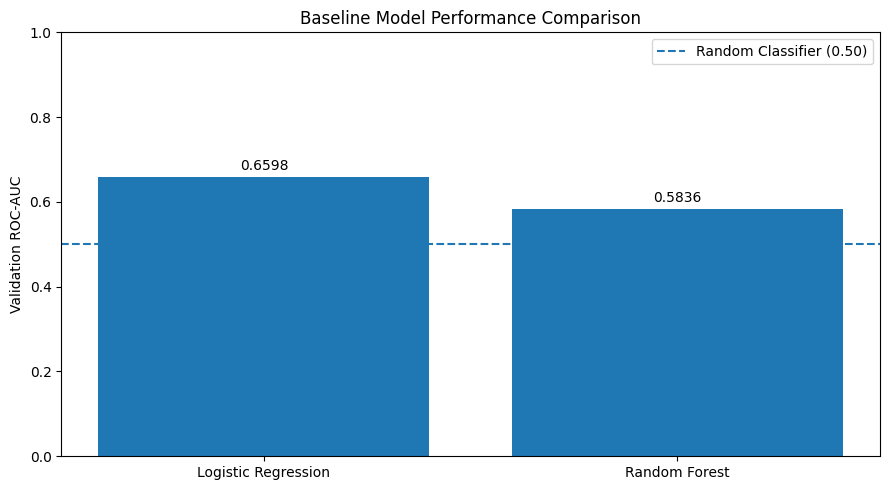

In [17]:
# ============================================================
# PHASE 08.1 — BASELINE MODEL COMPARISON
# ============================================================

model_names = [
    "Logistic Regression",
    "Random Forest"
]

roc_auc_scores = [
    lr_roc_auc,
    rf_roc_auc
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    roc_auc_scores
)

plt.axhline(
    y=0.5,
    linestyle="--",
    label="Random Classifier (0.50)"
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Validation ROC-AUC")
plt.ylim(0, 1)

plt.legend()

# Display score above each bar
for bar, score in zip(bars, roc_auc_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [ ]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [ ]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIGlobal/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [ ]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"

[Errno 2] No such file or directory: '/content/drive/MyDrive/WhereThisNotebookIsLocated'
/content


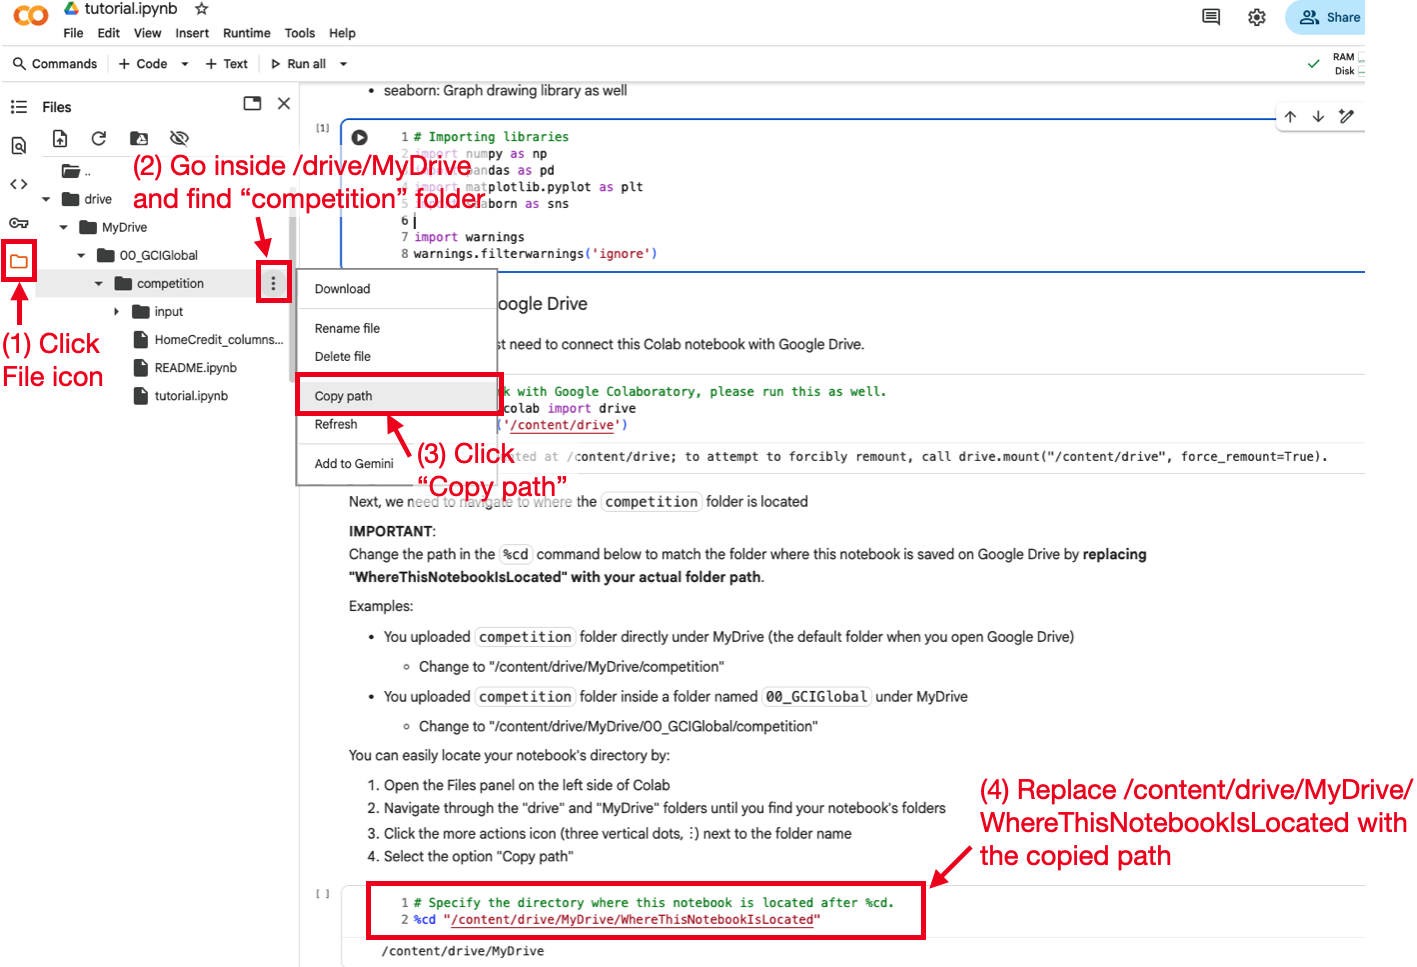

Run the cell below to check if the path is correctly set.

In [ ]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

Some files are missing or path is not correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [ ]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

FileNotFoundError: [Errno 2] No such file or directory: '/content/input/train.csv'

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [ ]:
# Focus on 5 features
use_features = [
    "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_2",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    # add new features to use here
]
target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

Let's check the data once again.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

### **[Next Steps]**
> + Try adding more features, starting with the ones that you think are more relevant for predicting default probability. Check `HomeCredit_columns_description.xlsx` to understand what each column represents.
> + When you add new features, always restart from [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [ ]:
# Check missing values of train data
train.isnull().sum()

In [ ]:
# Check missing values of test data
test.isnull().sum()

We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

In [ ]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

In [ ]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL column

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

In [ ]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE column

In [ ]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [ ]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

train.head(5)

### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [ ]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(5)

### EXT_SOURCE_2 column
Fill missing values in `EXT_SOURCE_2`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [ ]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True) # Use average of train data to fill test data

train.isnull().sum()

### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [ ]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [ ]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

In [ ]:
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [ ]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [ ]:
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [ ]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [ ]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

Now, let's create models with logistic regression and random forest.

In [ ]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

We find that random forest results with higher validation score.

### 5.4 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [ ]:
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2

print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

We find that in this case, ensemble leaning does not contribute to improved score. So, **we will use the random forest model as the final model to make predictions on the test data**.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [ ]:
# Make predictions for the test data
# Change model name if needed
pred = rf.predict_proba(X_test_std)[:, 1]

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")